# Start of execution

In [1]:
import time
start = time.time()

# Criteo Display Advertising — Click-Through Rate (CTR) Prediction

**Paradigm:** Supervised learning · **Industry:** 📢 Online advertising · **Feedback:** Implicit (clicks)

---

## 1. Business Understanding

### 1.1 Context
Every time a user opens a web page or an app, an **ad auction** happens in a few milliseconds. Advertising platforms such as Criteo decide **which ad to show** and **how much to bid** for that impression. Most advertisers pay **per click** (cost-per-click, CPC), so the platform only earns money if the user clicks.

The expected value of showing an ad is therefore:

**Expected revenue of an impression = P(click | user, ad, context) × price per click**

The probability of a click, the **click-through rate (CTR)**, is the core quantity behind every bidding and ranking decision.

### 1.2 Business Problem
> **Given an impression (user, ad, publisher and context), what is the probability that the user clicks on the ad?**

That estimate is used to:
- **Rank ads:** show the ad with the highest expected value (pCTR × bid).
- **Bid:** decide how much to pay for an impression. Overestimating the CTR wastes the advertiser's budget, and underestimating it loses auctions.
- **Recommend:** CTR models are the **ranking stage of industrial recommender systems** (ads, news feeds, product carousels). The candidate generators of the previous projects produce a shortlist, and a CTR model decides the final order.

### 1.3 Why Calibrated Probabilities Matter
In the previous projects only the **order** of the recommendations mattered (Precision@K, NDCG). Here the **probability itself** is used in money calculations:
- A model that ranks ads well but predicts 10% instead of 5% makes the platform **bid twice too much**.
- The model must therefore be both **discriminative** (separate clicks from non-clicks) and **calibrated** (predicted 5% ≈ observed 5%).

### 1.4 Data
The **Criteo Display Advertising Challenge** dataset (Kaggle, 2014) is a standard benchmark for CTR models in research:
- About **45 million impressions** collected over **7 consecutive days**, in chronological order.
- **Label:** 1 if the ad was clicked, 0 otherwise. Non-clicks were subsampled, so the CTR in the data is much higher than in real traffic.
- **13 integer features** (`I1`–`I13`), mostly counts.
- **26 categorical features** (`C1`–`C26`), **anonymized and hashed** into 8-character codes. Some have millions of distinct values.
- The meaning of the features is **not disclosed**, so we cannot use domain knowledge. The model has to learn from the data alone.

Working with all 45M rows does not fit in Colab's memory, so we use a **chronological sample** (details in Section 2).

### 1.5 Machine Learning Formulation
- **Task:** binary classification, with predicted probabilities as the output.
- **Validation:** **temporal split.** The model is trained on earlier impressions and evaluated on later ones, as in production (no shuffling, no future information).
- **Main challenges:**
  - **High-cardinality categorical features:** millions of hashed values, most of them rare.
  - **Feature interactions:** the click probability depends on *combinations* (this ad × this site × this time), not on single features.
  - **Sparsity and scale:** the models need to be memory-efficient.

### 1.6 Evaluation Metrics
| Metric | What it measures | Why it matters |
|---|---|---|
| **Log loss** (main) | Quality of the predicted probabilities | Official Kaggle metric; directly penalizes miscalibrated bids |
| **ROC AUC** | Ranking: P(a random click scores higher than a random non-click) | How well the model orders impressions |
| **Relative improvement in log loss** vs. the baseline | Gain over predicting the average CTR for everyone | Normalizes for the base rate |
| **Calibration** (predicted vs. observed CTR by bucket) | Whether a predicted 20% really means 20% | Needed for bidding |

In CTR prediction, improvements look small in absolute terms: an improvement of **0.001 in log loss** is widely considered significant at this scale, because it applies to billions of impressions.

### 1.7 Approach
| Step | Models | Idea |
|---|---|---|
| Baselines | Global CTR, per-feature CTR (target encoding) | How much information single features carry |
| Linear | **Logistic regression** with one-hot / hashed features | The classic industry workhorse: fast, calibrated, interpretable |
| Trees | **LightGBM** with frequency and target encoding | Captures non-linearities and interactions automatically |
| Factorization | **Factorization Machines (FM)** | Learns an embedding per feature value and models all pairwise interactions |
| Deep learning | **DeepFM** (FM + neural network), in PyTorch on GPU | Combines low-order and high-order interactions |

### 1.8 How This Project Complements the Repository
| | Instacart | MovieLens | Amazon | **Criteo** |
|---|---|---|---|---|
| Industry | Retail | Media | E-commerce | **Advertising** |
| Paradigm | Supervised + unsupervised | Supervised + unsupervised | Self-supervised + unsupervised | **Supervised** |
| Signal | Purchases | Star ratings | Ordered interactions | **Clicks on impressions** |
| Output | Ranked list + list size | Rating + ranked list | Ranked list | **Calibrated probability** |
| Main metric | F1 | RMSE / NDCG@10 | HR@10 / NDCG@10 | **Log loss / AUC** |
| Key difficulty | Repetition, list size | Rating vs. ranking | Order and recency | **Anonymous high-cardinality features** |

## 2. Setup and Data

| File | Content | Source |
|---|---|---|
| `dac.tar.gz` (\~4.3 GB) | `train.txt`: \~45.8M labeled impressions over 7 days, chronologically ordered (tab-separated) | Criteo Display Advertising Challenge, official archive (figshare mirror) |
| `criteo_sample.parquet` | Chronological 1-in-5 sample, with types optimized for memory | Created by this notebook |

**Sampling strategy:**
- The full file (\~11 GB uncompressed, 45.8M rows) does not fit comfortably in Colab's RAM, so it is **streamed** directly from the compressed archive in chunks of 1M rows.
- We keep **every 5th row** (a systematic sample). The rows are in chronological order, so the sample still covers **all 7 days in order**, and a temporal split remains valid.
- Each categorical value is an 8-character hexadecimal hash, which we convert to a 32-bit integer (4 bytes instead of \~60 bytes per Python string). Missing values become 0.

*The data is subject to Criteo's terms of use. It is not redistributed in this repository.*

In [2]:
# ==============================
# Imports and configuration
# ==============================
import warnings, gc, tarfile, zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import torch

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)

DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)
SEED = 42
np.random.seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {DEVICE}" + (f" ({torch.cuda.get_device_name(0)})" if DEVICE == "cuda" else ""))

# Columns of the original file
INT_COLS = [f"I{i}" for i in range(1, 14)]
CAT_COLS = [f"C{i}" for i in range(1, 27)]
COLS = ["label"] + INT_COLS + CAT_COLS

# Plot style (same palette as the other projects)
BLUE, ORANGE, GREEN, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8a85"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "axes.titleweight": "bold", "axes.titlesize": 12,
})

def pct_axis(ax, axis="y", decimals=0):
    fmt = mtick.PercentFormatter(1.0, decimals=decimals)
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(fmt)

Device: cuda (NVIDIA A100-SXM4-40GB)


In [3]:
# ==============================
# Download the official archive (skipped if the sample already exists)
# ==============================
SAMPLE_PATH = DATA_DIR / "criteo_sample.parquet"
TAR_PATH = DATA_DIR / "dac.tar.gz"
ZIP_PATH = DATA_DIR / "criteo-dataset.zip"           # alternative: Kaggle mirror
URL = "https://ndownloader.figshare.com/files/10082655"

if SAMPLE_PATH.exists():
    print(f"Sample already available: {SAMPLE_PATH} — download skipped.")
elif TAR_PATH.exists() or ZIP_PATH.exists():
    print("Archive already downloaded.")
else:
    !wget -c -q --show-progress -O {TAR_PATH} "{URL}"

for p in [TAR_PATH, ZIP_PATH, SAMPLE_PATH]:
    if p.exists():
        print(f"{p.name}: {p.stat().st_size / 1e9:.2f} GB")

# ---- Fallback if the figshare download fails (uncomment) ----
# Needs kaggle.json (Kaggle → Settings → API → Create New Token); no competition rules to accept.
# !mkdir -p ~/.kaggle && cp kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
# !kaggle datasets download -d mrkmakr/criteo-dataset -p {DATA_DIR}

Sample already available: data/criteo_sample.parquet — download skipped.
dac.tar.gz: 4.58 GB
criteo_sample.parquet: 0.52 GB


### 2.1 Streaming, Sampling and Type Optimization
The archive is read as a stream, one chunk of 1M rows at a time. For each chunk we keep every 5th row (by global row number), convert the types, and append the result. The final sample is saved as Parquet.

| Column | Original | Stored as |
|---|---|---|
| `label` | 0/1 text | `int8` |
| `I1`–`I13` | integer text, possibly empty | `float32` (missing → NaN) |
| `C1`–`C26` | 8-character hex hash, possibly empty | `uint32` (missing → 0) |
| `row` | — | global row number in the original file (keeps the time order) |

In [4]:
# ==============================
# Stream the archive, keep 1 row in STEP, optimize types, save Parquet
# ==============================
import subprocess

STEP = 5                     # keep every 5th row  →  ~9.2M impressions
CHUNK = 1_000_000

def open_train_stream():
    """Yield chunks of train.txt from the compressed archive, decompressed on the fly by the system's tar/unzip."""
    read_kw = dict(sep="\t", header=None, names=COLS, chunksize=CHUNK,
                   dtype={**{"label": "int8"}, **{c: "float32" for c in INT_COLS}, **{c: "string" for c in CAT_COLS}})
    if TAR_PATH.exists():
        cmd = ["tar", "-xzOf", str(TAR_PATH), "--wildcards", "*train.txt"]     # -O: write to stdout, no extraction to disk
    else:
        cmd = ["unzip", "-p", str(ZIP_PATH), "*train.txt"]                      # -p: write to stdout (Kaggle mirror)
    proc = subprocess.Popen(cmd, stdout=subprocess.PIPE, bufsize=1 << 20)
    try:
        yield from pd.read_csv(proc.stdout, **read_kw)
    finally:
        proc.stdout.close()
        proc.wait()

def hex_to_uint32(s):
    return s.fillna("0").map(lambda x: int(x, 16)).astype("uint32")

if not SAMPLE_PATH.exists():
    t0 = time.time()
    parts, offset = [], 0
    for k, chunk in enumerate(open_train_stream()):
        rows = np.arange(offset, offset + len(chunk))
        keep = chunk[rows % STEP == 0].copy()
        keep.insert(0, "row", rows[rows % STEP == 0].astype("int32"))
        for c in CAT_COLS:
            keep[c] = hex_to_uint32(keep[c])
        parts.append(keep)
        offset += len(chunk)
        if k % 5 == 0:
            print(f"  {offset / 1e6:5.1f}M rows read | {sum(len(p) for p in parts) / 1e6:.2f}M kept | {(time.time() - t0) / 60:.1f} min")
    df = pd.concat(parts, ignore_index=True)
    del parts; gc.collect()
    df.to_parquet(SAMPLE_PATH, index=False)
    N_TOTAL = offset
    print(f"\nRows in the original file: {N_TOTAL:,} | sample: {len(df):,} | {(time.time() - t0) / 60:.1f} min")
else:
    df = pd.read_parquet(SAMPLE_PATH)
    N_TOTAL = None                                               # unknown when loading from cache

print(f"Sample shape: {df.shape} | memory: {df.memory_usage(deep=True).sum() / 1e9:.2f} GB")
print(f"Overall CTR in the sample: {df['label'].mean():.2%}")
display(df.head())

Sample shape: (9168124, 41) | memory: 1.48 GB
Overall CTR in the sample: 25.61%


,row,label,I1,I2,I3,I4,I5,I6,I7,I8,I9,I10,I11,I12,I13,C1,C2,C3,C4,C5,C6,C7,C8,C9,C10,C11,C12,C13,C14,C15,C16,C17,C18,C19,C20,C21,C22,C23,C24,C25,C26
0,0,0,1.0,1.0,5.0,0.0,1382.0,4.0,15.0,2.0,181.0,1.0,2.0,NaN,2.0,1761418852,2162322587,4220739894,2068259780,633879704,2114768079,3732510136,529118562,2805916944,2832028932,2999688344,935969124,673490422,450684655,2343089050,2300273383,3854202482,4114618041,568184265,2972002973,129309004,0,974593739,3318023300,3904386055,2535972118
1,5,0,NaN,-1.0,NaN,NaN,12824.0,NaN,0.0,0.0,6.0,NaN,0.0,NaN,NaN,98275684,1822203123,657517724,1409342347,1135711049,1869454312,1404434808,185940084,2805916944,990438539,2447965223,3192240247,2683387682,131152527,110533152,2613575669,2003624857,2455065187,0,0,606844688,2395567348,3195814324,1925680913,0,0
2,10,0,NaN,2.0,632.0,0.0,56770.0,NaN,0.0,5.0,65.0,NaN,0.0,NaN,2.0,98275684,73979506,2062028047,2161661274,633879704,2114768079,69696505,185940084,2093428418,990438539,2116836373,3486017542,2443294225,2995026422,1478826667,342520061,2003624857,187896596,568184265,1480633834,3421256155,0,974593739,3470446969,3935970412,2589289724
3,15,0,NaN,2.0,1.0,18.0,20255.0,NaN,0.0,1.0,1306.0,NaN,0.0,NaN,20.0,98275684,3161341377,1736023145,3490516789,1291264903,2114768079,3394230520,1683111162,2805916944,990438539,2684750794,3119680563,584202924,1525414787,3607261498,258299472,2003624857,975186173,0,0,3022437523,0,974593739,772407349,0,0
4,20,1,NaN,47.0,NaN,0.0,6399.0,38.0,19.0,10.0,143.0,NaN,10.0,NaN,6.0,342162125,950618017,574295574,3394569756,633879704,2114768079,1765007041,1530472565,2805916944,990438539,2248945707,359635439,812864628,450684655,242755870,1606371972,3854202482,429505257,0,0,3736690781,0,851920782,3829933919,0,0


## 3. Data Quality

**Questions:**
- **Time structure:** can we recover the 7 days and build a temporal train / validation / test split?
- **Missing values:** how many are there per feature? Could missingness itself be informative?
- **Categorical features:** how many distinct values does each one have, and how many are rare?
- **Integer features:** ranges, negative values, skewness?
- **Duplicates:** are there repeated impressions?
- **Unseen categories:** how many test values never appear in training? This is the main generalization risk for models that learn one parameter per category.

**Temporal split.** The rows are chronologically ordered, but the file has no timestamp. We approximate each **day as 1/7 of the rows** (the standard convention in benchmarks that split Criteo by day):

| Split | Days | Role |
|---|---|---|
| Train | 1–5 | Fit the models |
| Validation | 6 | Tune hyperparameters and early stopping |
| Test | 7 | Final, untouched evaluation |

By day:


,impressions,ctr
day,,
1,"1,309,732",24.84%
2,"1,309,732",25.64%
3,"1,309,732",25.47%
4,"1,309,732",25.36%
5,"1,309,732",26.32%
6,"1,309,732",25.73%
7,"1,309,732",25.95%


By split:


,impressions,ctr,share
split,,,
train,"6,548,660",25.53%,71.4%
valid,"1,309,732",25.73%,14.3%
test,"1,309,732",25.95%,14.3%


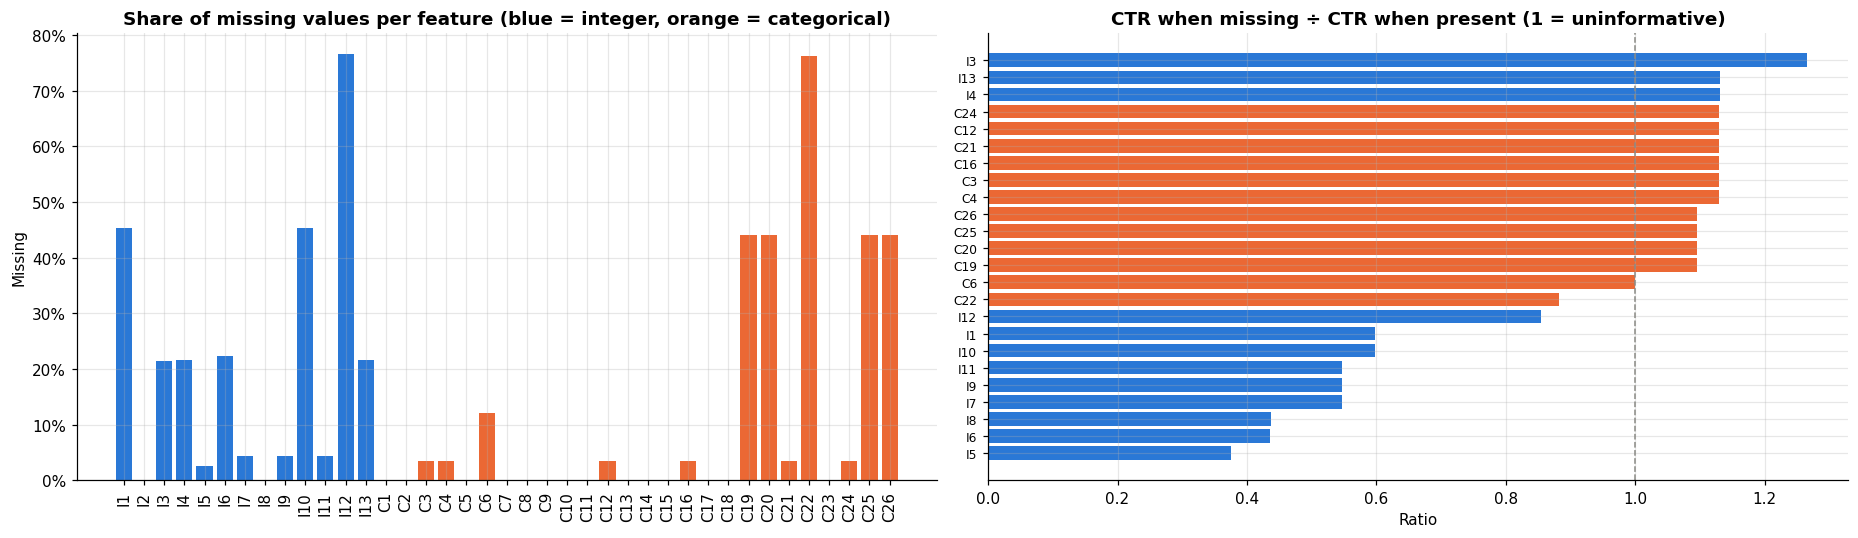

Rows with at least one missing value: 98.4%
Average missing values per row: 5.5 of 39

Impressions whose 39 features are identical to another one: 0.01%
  of which with conflicting labels: 120 groups


57

In [5]:
# ==============================
# 3.1 Days and temporal split
# ==============================
N_ORIGINAL = N_TOTAL if N_TOTAL else 45_840_617                      # rows in the original train.txt
df["day"] = (df["row"].astype("int64") * 7 // N_ORIGINAL + 1).astype("int8")
df["split"] = pd.Categorical(np.select([df["day"] <= 5, df["day"] == 6], ["train", "valid"], "test"),
                             categories=["train", "valid", "test"], ordered=True)

by_day = df.groupby("day").agg(impressions=("label", "size"), ctr=("label", "mean"))
by_split = df.groupby("split", observed=True).agg(impressions=("label", "size"), ctr=("label", "mean"))
by_split["share"] = by_split["impressions"] / len(df)
print("By day:");   display(by_day.style.format({"impressions": "{:,}", "ctr": "{:.2%}"}))
print("By split:"); display(by_split.style.format({"impressions": "{:,}", "ctr": "{:.2%}", "share": "{:.1%}"}))

# ==============================
# 3.2 Missing values
# ==============================
missing = pd.concat([df[INT_COLS].isna().mean(), (df[CAT_COLS] == 0).mean()]).rename("missing")

# Is missingness informative? CTR when the feature is missing vs. present
miss_ctr = []
for c in INT_COLS + CAT_COLS:
    m = df[c].isna() if c in INT_COLS else df[c] == 0
    if 0 < m.mean() < 1:
        miss_ctr.append({"feature": c, "ctr_missing": df.loc[m, "label"].mean(), "ctr_present": df.loc[~m, "label"].mean()})
miss_ctr = pd.DataFrame(miss_ctr).set_index("feature")
miss_ctr["ratio"] = miss_ctr["ctr_missing"] / miss_ctr["ctr_present"]

fig, axes = plt.subplots(1, 2, figsize=(17, 5))
colors = [BLUE if c.startswith("I") else ORANGE for c in missing.index]
axes[0].bar(missing.index, missing.values, color=colors)
axes[0].set(title="Share of missing values per feature (blue = integer, orange = categorical)", ylabel="Missing")
axes[0].tick_params(axis="x", rotation=90)
pct_axis(axes[0])

r = miss_ctr["ratio"].sort_values()
axes[1].barh(r.index, r.values, color=[BLUE if c.startswith("I") else ORANGE for c in r.index])
axes[1].axvline(1, color=GREY, ls="--", lw=1)
axes[1].set(title="CTR when missing ÷ CTR when present (1 = uninformative)", xlabel="Ratio")
axes[1].tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()

print(f"Rows with at least one missing value: {(df[INT_COLS].isna().any(axis=1) | (df[CAT_COLS] == 0).any(axis=1)).mean():.1%}")
print(f"Average missing values per row: {df[INT_COLS].isna().sum(axis=1).mean() + (df[CAT_COLS] == 0).sum(axis=1).mean():.1f} of 39")

# ==============================
# 3.3 Duplicated impressions
# ==============================
h = pd.util.hash_pandas_object(df[INT_COLS + CAT_COLS], index=False)
dup = h.duplicated(keep=False)
print(f"\nImpressions whose 39 features are identical to another one: {dup.mean():.2%}")
print(f"  of which with conflicting labels: {(df.loc[dup].groupby(h[dup])['label'].nunique() > 1).sum():,} groups")
del h; gc.collect()

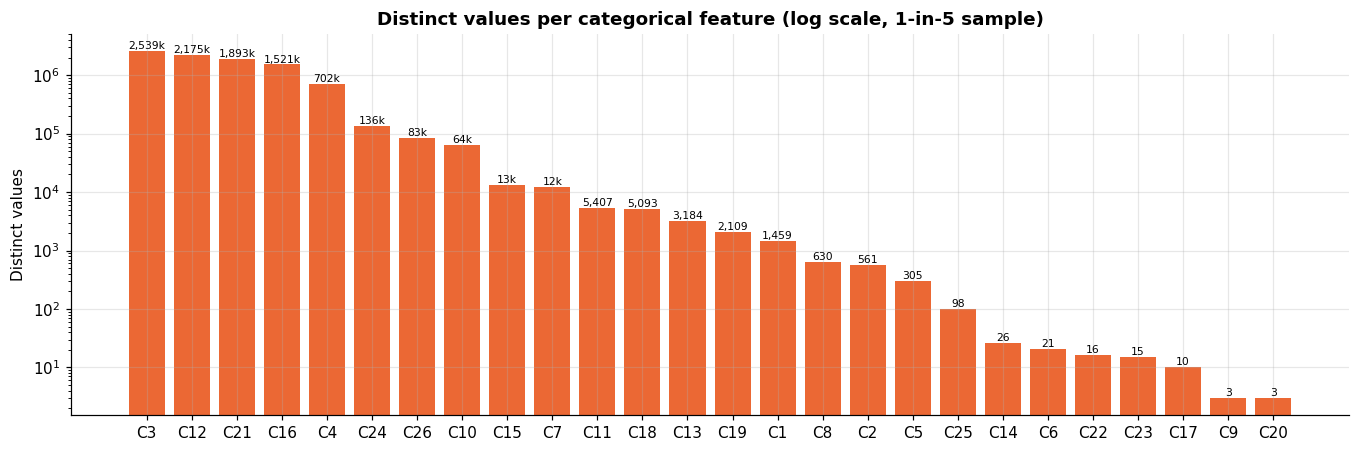

,distinct,values_seen_once,rows_in_values_<10,top_value_share
feature,,,,
C3,"2,538,827",87.0%,33.9%,2.5%
C12,"2,174,980",85.0%,29.8%,2.5%
C21,"1,893,404",83.3%,26.5%,2.5%
C16,"1,520,881",80.9%,22.0%,2.5%
C4,"701,546",72.0%,11.2%,3.6%
C24,"135,775",47.2%,2.7%,5.2%
C26,"82,831",36.7%,1.7%,4.1%
C10,"63,953",26.7%,1.2%,22.2%
C15,"13,044",10.6%,0.2%,1.5%


Total distinct categorical values (all 26 features): 9,156,411


,count,min,50%,90%,99%,max,negative_share,zero_share,skew
I1,"5,008,935",0,1,9,39,"1,781",0.00%,23.2%,16.2
I2,"9,168,124",-3,3,183,"2,240","21,116",10.35%,17.4%,7.1
I3,"7,199,655",0,6,44,221,"65,535",0.00%,0.3%,84.0
I4,"7,181,788",0,4,18,40,806,0.00%,4.2%,4.4
I5,"8,931,113",0,"2,813","34,169","348,585","23,159,456",0.00%,1.8%,13.3
I6,"7,116,408",0,32,272,"1,287","431,037",0.00%,5.1%,314.4
I7,"8,769,979",0,3,34,217,"56,311",0.00%,21.6%,99.1
I8,"9,163,592",0,7,34,48,"5,838",0.00%,11.5%,74.7
I9,"8,769,979",0,38,264,987,"20,065",0.00%,3.0%,8.5
I10,"5,008,935",0,1,1,3,11,0.00%,26.1%,1.1


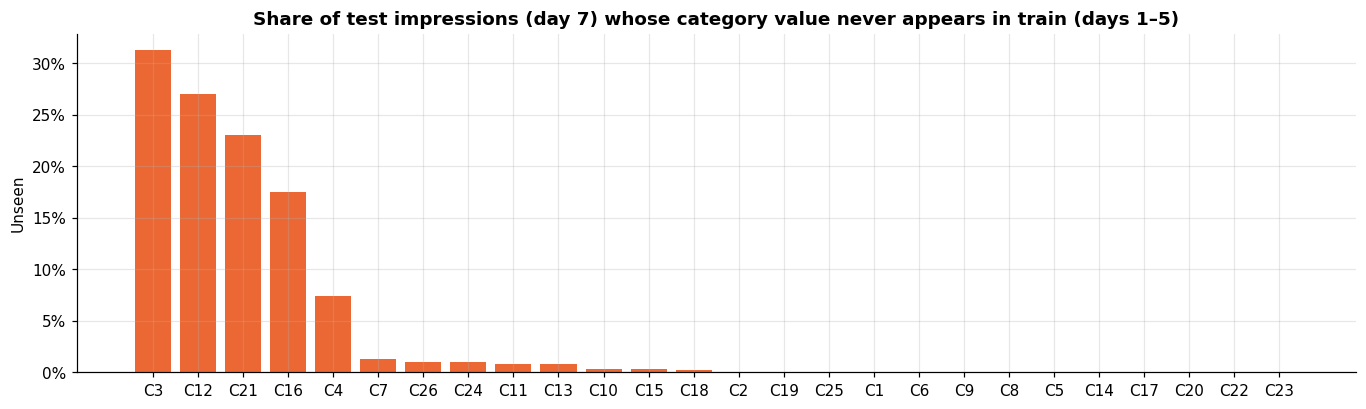

,test_rows_unseen,ctr_unseen,ctr_seen
feature,,,
C3,31.3%,27.6%,25.0%
C12,27.0%,28.1%,25.0%
C21,23.0%,27.7%,25.3%
C16,17.5%,28.0%,25.4%
C4,7.4%,27.1%,25.7%
C7,1.3%,20.7%,26.0%
C26,1.0%,25.7%,24.9%
C24,1.0%,21.8%,25.9%
C11,0.8%,15.3%,26.0%


Test impressions with at least one unseen categorical value: 31.7%


In [6]:
# ==============================
# 3.4 Categorical cardinality and rare values
# ==============================
card = []
for c in CAT_COLS:
    vc = df.loc[df[c] != 0, c].value_counts()
    card.append({"feature": c, "distinct": len(vc),
                 "values_seen_once": (vc == 1).mean(),
                 "rows_in_values_<10": vc[vc < 10].sum() / len(df),
                 "top_value_share": vc.iloc[0] / len(df) if len(vc) else 0})
card = pd.DataFrame(card).set_index("feature").sort_values("distinct", ascending=False)

fig, ax = plt.subplots(figsize=(15, 4.5))
ax.bar(card.index, card["distinct"], color=ORANGE)
ax.set_yscale("log")
ax.set(title="Distinct values per categorical feature (log scale, 1-in-5 sample)", ylabel="Distinct values")
for x, v in enumerate(card["distinct"]):
    ax.text(x, v, f"{v:,.0f}" if v < 1e4 else f"{v / 1e3:,.0f}k", ha="center", va="bottom", fontsize=7)
plt.show()
display(card.style.format({"distinct": "{:,}", "values_seen_once": "{:.1%}", "rows_in_values_<10": "{:.1%}", "top_value_share": "{:.1%}"}))
print(f"Total distinct categorical values (all 26 features): {card['distinct'].sum():,}")

# ==============================
# 3.5 Integer features
# ==============================
desc = df[INT_COLS].describe(percentiles=[.5, .9, .99]).T
desc["negative_share"] = (df[INT_COLS] < 0).mean()
desc["zero_share"] = (df[INT_COLS] == 0).mean()
desc["skew"] = df[INT_COLS].skew()
display(desc[["count", "min", "50%", "90%", "99%", "max", "negative_share", "zero_share", "skew"]]
        .style.format({"count": "{:,.0f}", "negative_share": "{:.2%}", "zero_share": "{:.1%}", "skew": "{:.1f}",
                       **{c: "{:,.0f}" for c in ["min", "50%", "90%", "99%", "max"]}}))

# ==============================
# 3.6 Unseen categories: test values never observed in train
# ==============================
tr, te = df["split"] == "train", df["split"] == "test"
unseen = []
for c in CAT_COLS:
    train_vals = set(df.loc[tr, c].unique())
    present = te & (df[c] != 0)
    is_new = ~df.loc[present, c].isin(train_vals)
    unseen.append({"feature": c, "test_rows_unseen": is_new.mean(),
                   "ctr_unseen": df.loc[present, "label"][is_new].mean(),
                   "ctr_seen": df.loc[present, "label"][~is_new].mean()})
unseen = pd.DataFrame(unseen).set_index("feature").sort_values("test_rows_unseen", ascending=False)

fig, ax = plt.subplots(figsize=(15, 4))
ax.bar(unseen.index, unseen["test_rows_unseen"], color=ORANGE)
ax.set(title="Share of test impressions (day 7) whose category value never appears in train (days 1–5)", ylabel="Unseen")
pct_axis(ax)
plt.show()
display(unseen.head(10).style.format("{:.1%}"))

any_unseen = np.zeros(te.sum(), dtype=bool)
for c in CAT_COLS:
    train_vals = set(df.loc[tr, c].unique())
    any_unseen |= (~df.loc[te, c].isin(train_vals)).values
print(f"Test impressions with at least one unseen categorical value: {any_unseen.mean():.1%}")

### 3. Data Quality — Key Findings

**1. The temporal split works, and CTR is stable across days.**
- Each day has **1,309,732 sampled impressions** (1/7 of the rows by construction).
- Daily CTR ranges from **24.84% (day 1) to 26.32% (day 5)**. Train: 25.53%, validation: 25.73%, test: 25.95%.
- The slight upward drift (+0.4 pp from train to test) is small but relevant for **calibration**: a model that predicts the training average will slightly under-predict on day 7.

**2. Missing values are everywhere, follow groups, and are informative.**
- **98.4%** of impressions have at least one missing value (5.5 of 39 features on average).
- Missingness comes in **blocks** with almost identical rates, which suggests features logged by the same source:
  - **C19, C20, C25, C26** (\~44%);
  - **I1, I10** (\~45%);
  - **I3, I4, I13** (\~21–22%);
  - **C3, C4, C12, C16, C21, C24** (\~3.5%).
- The most incomplete features are **I12 (\~77%)** and **C22 (\~76%)**.
- **Missingness predicts clicks.** When integer features I5, I6 or I8 are missing, CTR is only **37–44%** of the CTR when they are present (ratio 0.37–0.44). Missing I3 *raises* CTR by 27%.
- **Decision:** never impute silently. A missing value is encoded as **its own category / bucket**, so the models can learn from it.

**3. Duplicates are negligible.**
- Only **0.01%** of impressions are exact copies of another one (120 groups with conflicting labels). No cleaning needed.

**4. Categorical features: a few giants with an enormous long tail.**
- The 26 categorical features have **9.16M distinct values in a 9.17M-row sample**, about one new value per impression.
- Five features concentrate the problem: **C3 (2.54M distinct), C12 (2.17M), C21 (1.89M), C16 (1.52M) and C4 (0.70M)**. **80–87%** of their values appear only once, and 22–34% of all impressions carry a value seen fewer than 10 times. These behave like **user- or ad-level identifiers**.
- At the other extreme, **C9 and C20 have 3 values**, C17 10, C23 15, C22 16 and C6 21. Several are dominated by one value (C9: 89.9%, C5: 67.1%, C8: 59.4%, C1: 50.1%).
- **Decision:** one parameter per raw value is impossible (and would overfit). Values seen **fewer than 10 times in training** are grouped into a per-feature `<OOV>` token, as in the winning Kaggle solution.

**5. Integer features: counts with extreme skew.**
- All integer features are non-negative except **I2** (10.35% negative, minimum −3), which probably uses negative codes for special cases.
- Skewness is extreme: **I6 (314)**, **I13 (108)**, **I7 (99)**, **I3 (84)**. **I5** has a median of 2,813 but a maximum of 23M.
- **I10** only takes values 0–11, so it is almost categorical. Many features have a large share of zeros (I10 26%, I1 23%, I11 22%, I7 22%).
- **Decision:** raw values are unusable for linear and neural models. They are **log-bucketed** (⌊ln(x)²⌋ for x > 2, as in the winning solution), with missing as its own bucket. Tree models can use the raw values.

**6. Unseen categories: 31.7% of test impressions carry at least one value never seen in training.**
- Unseen rate in test (day 7 vs. days 1–5): **C3 31.3%**, **C12 27.0%**, **C21 23.0%**, **C16 17.5%**, **C4 7.4%**. Every other feature is ≤ 1.3%.
- Only 31.7% of test impressions have *any* unseen value, barely above C3 alone, so the giant features tend to be **unseen together**. This suggests they encode related entities (e.g., the same user or ad hashed several ways). Section 4 checks this redundancy.
- New values click slightly **more** for the giant features (27–28% vs. 25%), and much **less** for C7, C11 and C13 (15–21% vs. 26%). Being unseen is itself a signal, which the `<OOV>` token captures.
- In the full dataset (5× more rows) these rates would be somewhat lower, but the problem would remain.

**Implications for modeling:**
- **Encoding:** `<OOV>` for rare / unseen values (threshold 10), missing as an explicit category, log-buckets for integers.
- **Models:** everything must generalize to unseen IDs. Factorization models share information through embeddings of the *other* features of the impression, which is their main advantage over one-hot logistic regression.
- **Evaluation:** log loss and calibration will be checked on day 7, which is slightly "hotter" than the training days.

## 4. Exploratory Data Analysis

The features are anonymous, so the EDA focuses on **predictive structure** rather than meaning.

**Encoding used from here on** (built once and reused by the models):
- **Categorical:** values seen fewer than 10 times in **train** → `<OOV>` (one per feature); missing → its own code.
- **Integer:** log-buckets ⌊ln(x)²⌋ for x > 2, raw value otherwise (including I2's negative codes); missing → its own bucket.
- Each feature is then mapped to consecutive integer codes (`X_ENC`, shape 9.17M × 39).

### 4.1 Univariate Predictive Power
**Question:** how much does each feature predict on its own?

For each feature we fit a **smoothed target encoding** on train (the CTR of each value, shrunk toward the global CTR with a prior of 20 impressions) and evaluate it on **validation**. Metrics:
- **AUC** of the encoded value;
- **relative log-loss reduction** vs. predicting the global training CTR for everyone (0% = no information).

X_ENC built in 0.8 min | total vocabulary: 254,161 codes


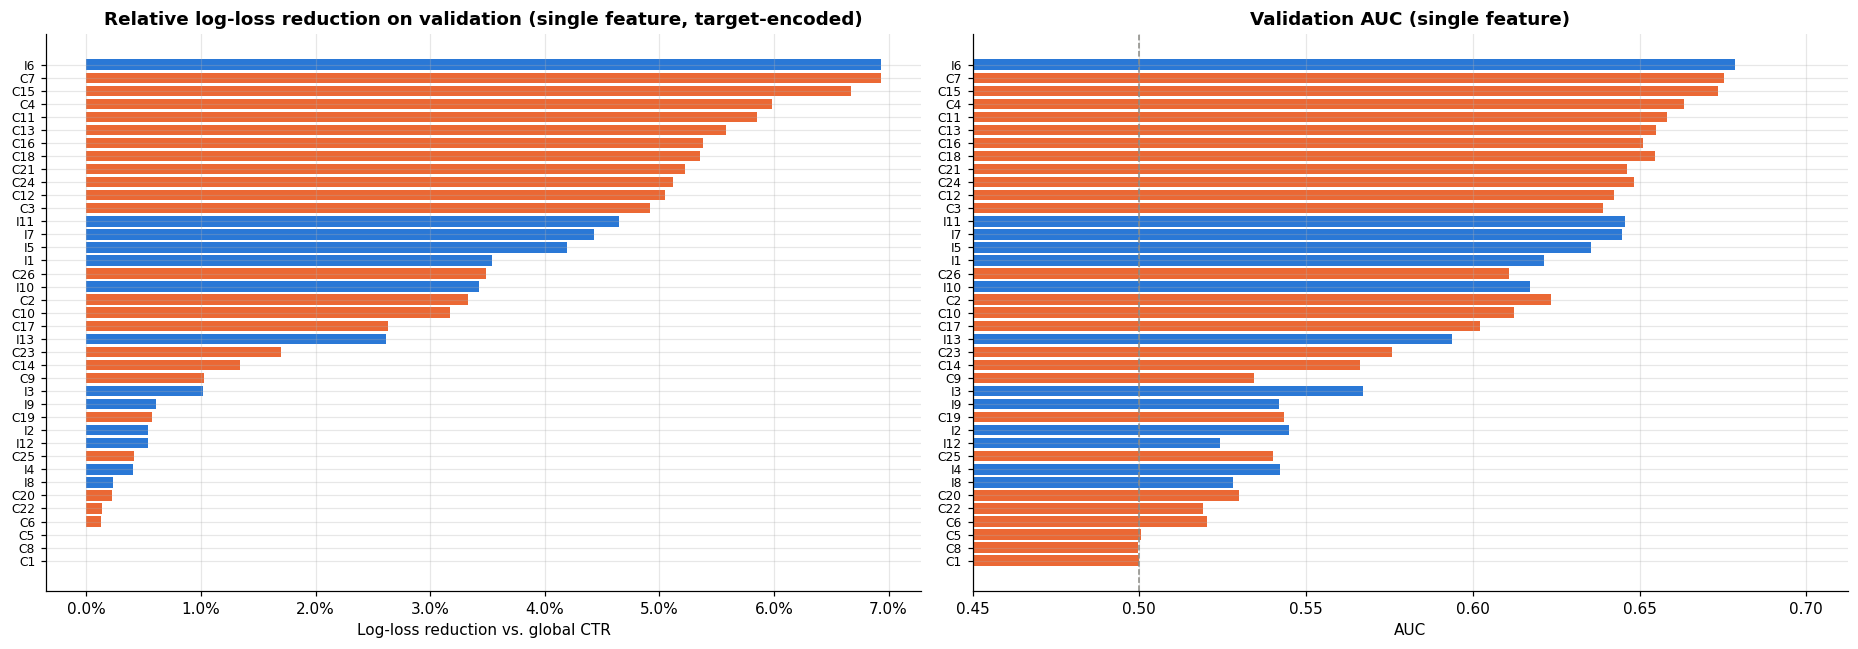

Global-CTR baseline on validation: log loss = 0.5702 (AUC = 0.5)


,type,vocab,AUC,logloss_gain
feature,,,,
I6,integer,132,0.679,6.94%
C7,categorical,"10,467",0.675,6.93%
C15,categorical,"7,731",0.674,6.67%
C4,categorical,"33,059",0.663,5.98%
C11,categorical,"4,585",0.658,5.85%
C13,categorical,"3,099",0.655,5.58%
C16,categorical,"33,301",0.651,5.38%
C18,categorical,"3,531",0.655,5.35%
C21,categorical,"33,017",0.646,5.22%


In [7]:
# ==============================
# 4.1 Encoding (X_ENC) and univariate predictive power
# ==============================
from sklearn.metrics import roc_auc_score, log_loss

FEATS = INT_COLS + CAT_COLS
MIN_COUNT = 10
M_PRIOR = 20

tr_m = (df["split"] == "train").values
va_m = (df["split"] == "valid").values
te_m = (df["split"] == "test").values
y = df["label"].values.astype(np.float32)
y_tr, y_va = y[tr_m], y[va_m]
P0 = y_tr.mean()
LL0 = log_loss(y_va, np.full(len(y_va), P0))

def int_bucket(x):
    x = x.to_numpy(dtype=np.float64)
    out = np.where(x > 2, np.floor(np.log(np.where(x > 2, x, 3)) ** 2) + 3, x)    # +3: keep buckets above raw values 0–2
    return np.where(np.isnan(x), -10, out).astype(np.int64)                         # missing → -10

def cat_oov(c):
    s = df[c].to_numpy(dtype=np.int64)
    vals, cnt = np.unique(s[tr_m], return_counts=True)
    frequent = vals[cnt >= MIN_COUNT]
    keep = np.isin(s, frequent) | (s == 0)                                          # 0 = missing (kept as its own code)
    return np.where(keep, s, -1)                                                    # -1 = <OOV> (rare or unseen)

t0 = time.time()
X_ENC = np.empty((len(df), len(FEATS)), dtype=np.int32)
VOCAB = {}
for j, c in enumerate(FEATS):
    raw = int_bucket(df[c]) if c in INT_COLS else cat_oov(c)
    X_ENC[:, j], uniques = pd.factorize(raw)
    VOCAB[c] = len(uniques)
print(f"X_ENC built in {(time.time() - t0) / 60:.1f} min | total vocabulary: {sum(VOCAB.values()):,} codes")

def te_valid(key, m=M_PRIOR):
    """Smoothed target encoding fitted on train, applied to validation."""
    K = int(key.max()) + 1
    s = np.bincount(key[tr_m], weights=y_tr, minlength=K)
    n = np.bincount(key[tr_m], minlength=K)
    return ((s + m * P0) / (n + m))[key[va_m]]

uni = []
for j, c in enumerate(FEATS):
    p = te_valid(X_ENC[:, j])
    uni.append({"feature": c, "type": "integer" if c in INT_COLS else "categorical", "vocab": VOCAB[c],
                "AUC": roc_auc_score(y_va, p), "logloss_gain": 1 - log_loss(y_va, p) / LL0})
uni = pd.DataFrame(uni).set_index("feature").sort_values("logloss_gain", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(17, 6))
cols = [BLUE if t == "integer" else ORANGE for t in uni["type"]]
axes[0].barh(uni.index[::-1], uni["logloss_gain"][::-1], color=cols[::-1])
axes[0].set(title="Relative log-loss reduction on validation (single feature, target-encoded)", xlabel="Log-loss reduction vs. global CTR")
pct_axis(axes[0], "x", 1)
axes[0].tick_params(axis="y", labelsize=8)
axes[1].barh(uni.index[::-1], uni["AUC"][::-1], color=cols[::-1])
axes[1].axvline(0.5, color=GREY, ls="--", lw=1)
axes[1].set(title="Validation AUC (single feature)", xlabel="AUC", xlim=(0.45, None))
axes[1].tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()

print(f"Global-CTR baseline on validation: log loss = {LL0:.4f} (AUC = 0.5)")
display(uni.head(15).style.format({"vocab": "{:,}", "AUC": "{:.3f}", "logloss_gain": "{:.2%}"}))
oov_share = {c: (X_ENC[te_m, j] == X_ENC[(cat_oov(c) == -1), j][0] if (cat_oov(c) == -1).any() else 0) for j, c in enumerate(FEATS[:0])}

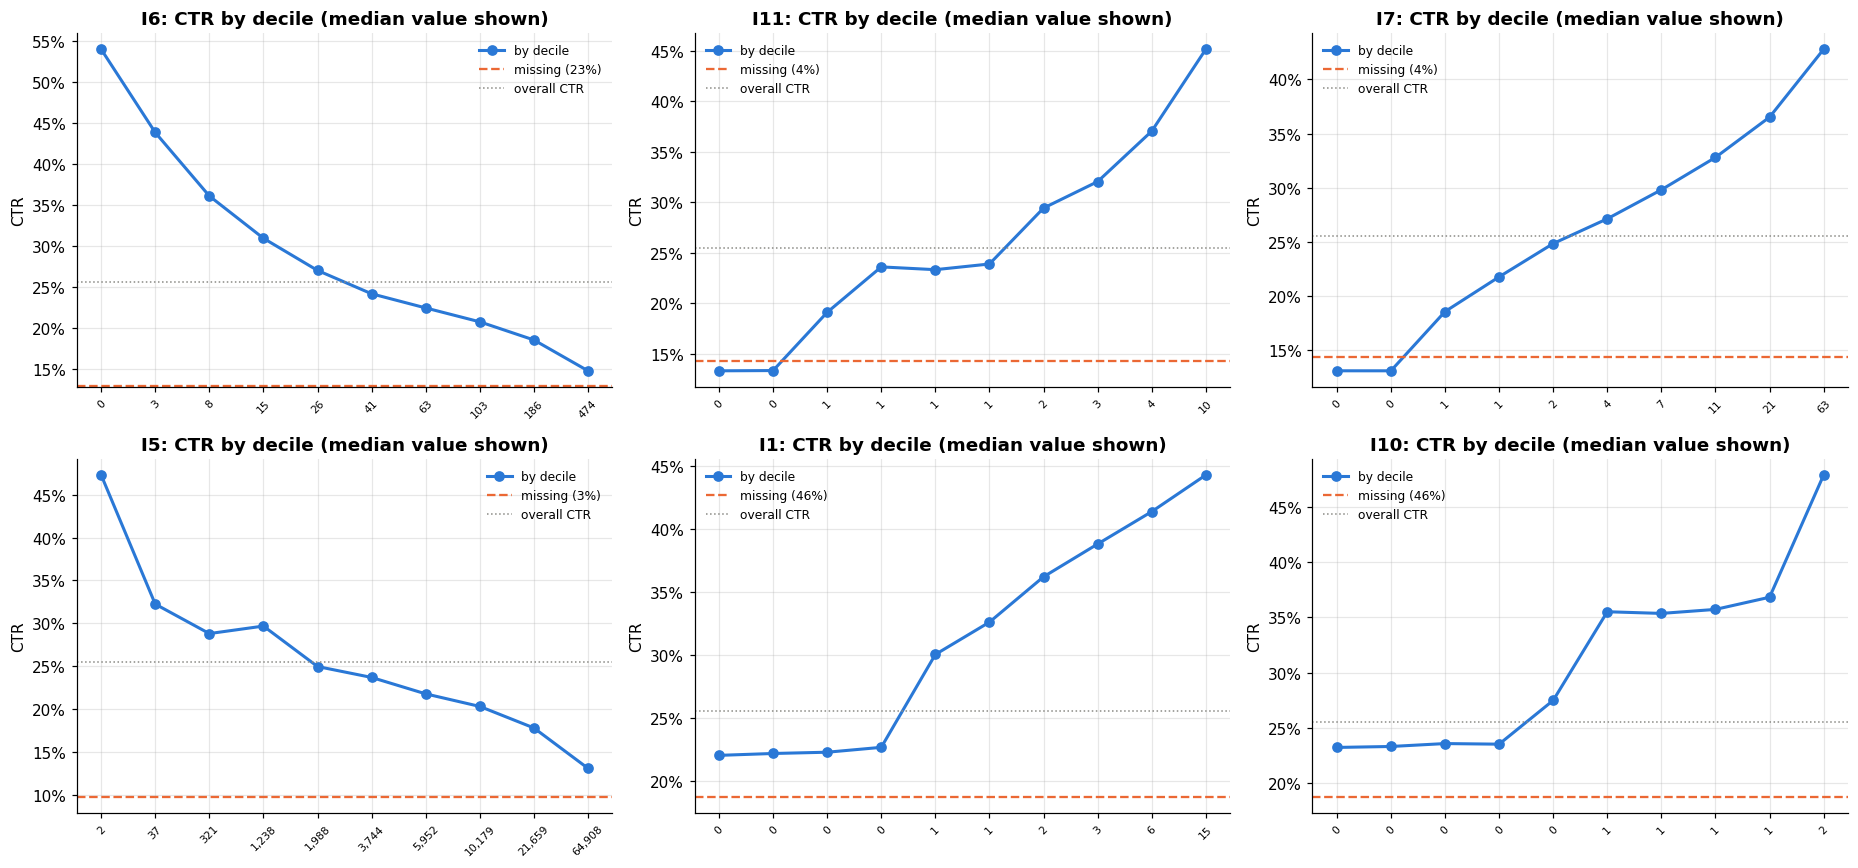

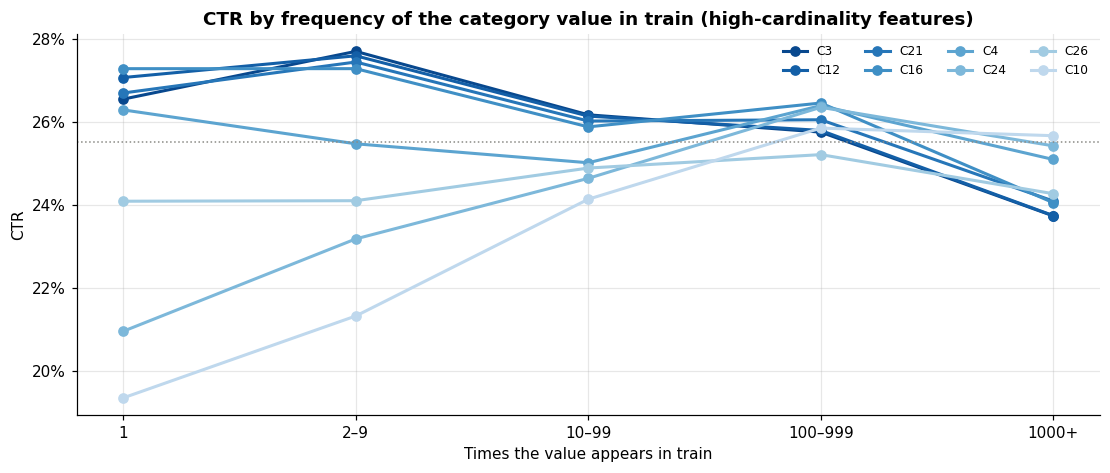

In [8]:
# ==============================
# 4.2 CTR vs. integer features (deciles of the raw value; missing shown separately)
# ==============================
top_int = uni[uni["type"] == "integer"].head(6).index.tolist()
trn = df[tr_m]

fig, axes = plt.subplots(2, 3, figsize=(17, 8))
for ax, c in zip(axes.ravel(), top_int):
    v = trn[c]
    present = v.notna()
    q = pd.qcut(v[present].rank(method="first"), 10, labels=False)
    g = trn.loc[present, "label"].groupby(q.values).mean()
    edges = v[present].groupby(q.values).median()
    ax.plot(range(10), g.values, color=BLUE, lw=2, marker="o", label="by decile")
    if (~present).any():
        ax.axhline(trn.loc[~present, "label"].mean(), color=ORANGE, ls="--", lw=1.5, label=f"missing ({(~present).mean():.0%})")
    ax.axhline(P0, color=GREY, ls=":", lw=1, label="overall CTR")
    ax.set_xticks(range(10))
    ax.set_xticklabels([f"{e:,.0f}" for e in edges], rotation=45, fontsize=7)
    ax.set(title=f"{c}: CTR by decile (median value shown)", ylabel="CTR")
    pct_axis(ax)
    ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

# ==============================
# 4.3 CTR vs. how frequent a categorical value is (train)
# ==============================
big = ["C3", "C12", "C21", "C16", "C4", "C24", "C26", "C10"]
fbins = [0, 1, 9, 99, 999, np.inf]
flabels = ["1", "2–9", "10–99", "100–999", "1000+"]

fig, ax = plt.subplots(figsize=(12, 4.5))
palette = sns.color_palette("Blues_r", len(big) + 2)
for k, c in enumerate(big):
    s = trn[c]
    s = s[s != 0]
    freq = s.map(s.value_counts())
    g = trn.loc[s.index, "label"].groupby(pd.cut(freq, fbins, labels=flabels), observed=True).mean()
    ax.plot(g.index.astype(str), g.values, lw=2, marker="o", color=palette[k], label=c)
ax.axhline(P0, color=GREY, ls=":", lw=1)
ax.set(title="CTR by frequency of the category value in train (high-cardinality features)",
       xlabel="Times the value appears in train", ylabel="CTR")
pct_axis(ax)
ax.legend(frameon=False, ncol=4, fontsize=8)
plt.show()

45 pairs evaluated in 0.5 min


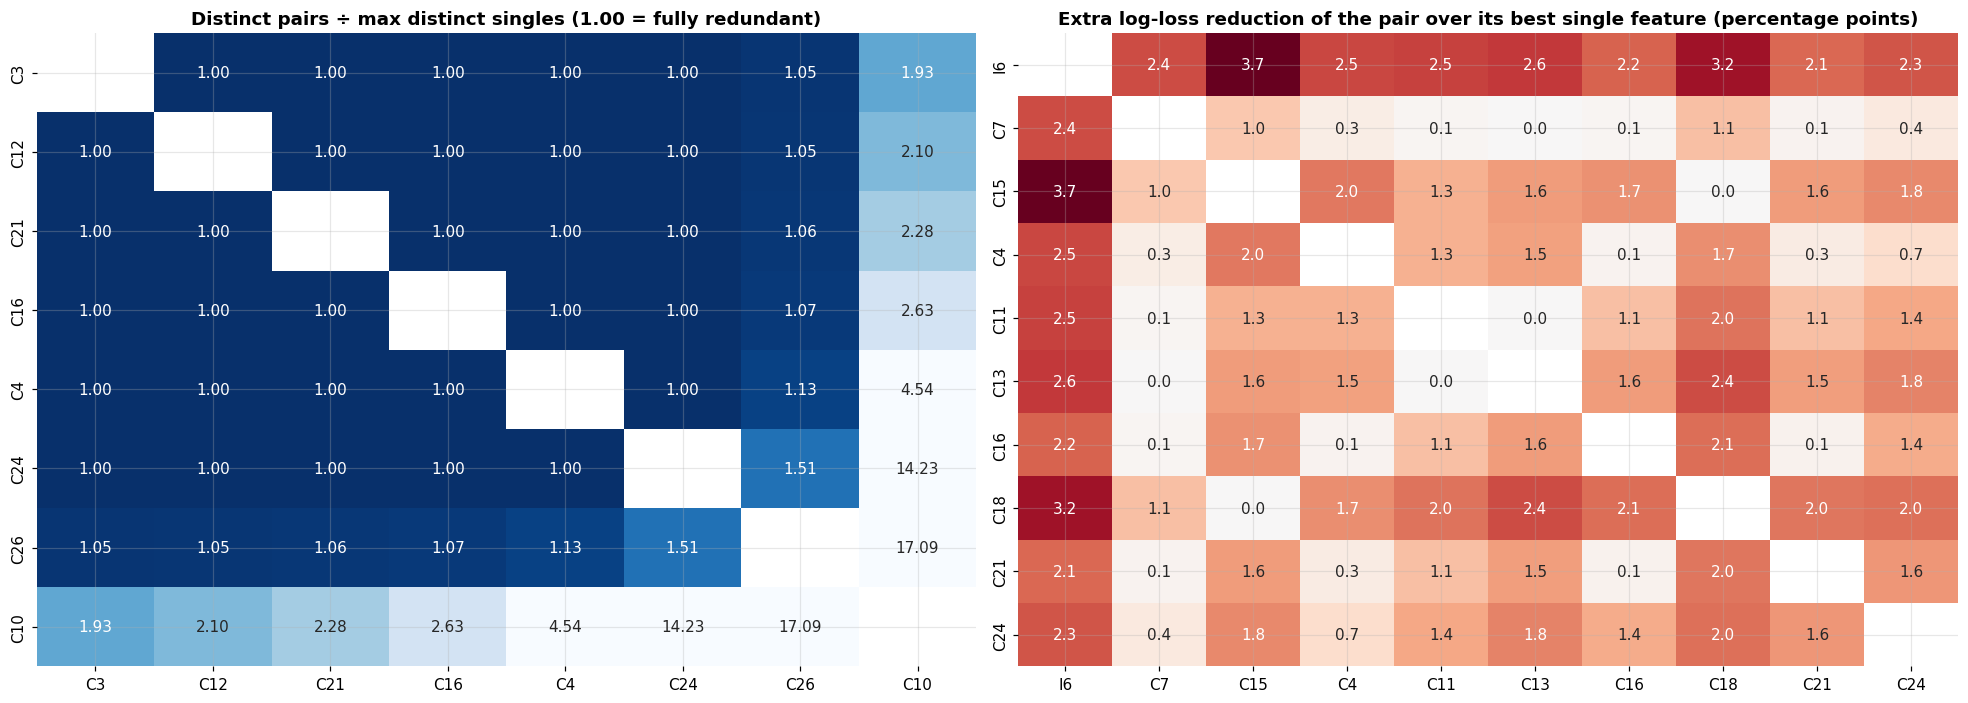

Strongest interactions (extra log-loss reduction, pp):


In [9]:
# ==============================
# 4.4 Redundancy among high-cardinality features
#     ratio = distinct (a, b) pairs / max(distinct a, distinct b); ≈ 1 → one feature almost determines the other
# ==============================
hc = ["C3", "C12", "C21", "C16", "C4", "C24", "C26", "C10"]
R = pd.DataFrame(np.nan, index=hc, columns=hc)
nuniq = {c: trn[c].nunique() for c in hc}
for i, a in enumerate(hc):
    for b in hc[i + 1:]:
        pair = (trn[a].to_numpy(np.uint64) << np.uint64(32)) | trn[b].to_numpy(np.uint64)
        R.loc[a, b] = R.loc[b, a] = len(pd.unique(pair)) / max(nuniq[a], nuniq[b])

fig, axes = plt.subplots(1, 2, figsize=(18, 6.5))
sns.heatmap(R, annot=True, fmt=".2f", cmap="Blues_r", vmin=1, vmax=3, cbar=False, ax=axes[0])
axes[0].set(title="Distinct pairs ÷ max distinct singles (1.00 = fully redundant)")

# ==============================
# 4.5 Pairwise interactions: does a pair predict better than its best member?
#     gain(pair) − max(gain(a), gain(b)), with target encoding on train, evaluated on validation
# ==============================
top10 = uni.head(10).index.tolist()
idx = {c: FEATS.index(c) for c in top10}
gain1 = uni["logloss_gain"]
I = pd.DataFrame(np.nan, index=top10, columns=top10)
t0 = time.time()
for i, a in enumerate(top10):
    for b in top10[i + 1:]:
        key = pd.factorize(X_ENC[:, idx[a]].astype(np.int64) * (VOCAB[b] + 1) + X_ENC[:, idx[b]])[0]
        g = 1 - log_loss(y_va, te_valid(key)) / LL0
        I.loc[a, b] = I.loc[b, a] = g - max(gain1[a], gain1[b])
print(f"45 pairs evaluated in {(time.time() - t0) / 60:.1f} min")

sns.heatmap(I * 100, annot=True, fmt=".1f", cmap="RdBu_r", center=0, cbar=False, ax=axes[1])
axes[1].set(title="Extra log-loss reduction of the pair over its best single feature (percentage points)")
plt.tight_layout()
plt.show()

pairs = I.where(np.triu(np.ones(I.shape, dtype=bool), 1)).stack().sort_values(ascending=False)
print("Strongest interactions (extra log-loss reduction, pp):")
display(pairs.head(8).mul(100).rename("extra_gain_pp").to_frame().style.format("{:+.2f}"))

### 4. EDA — Key Findings

**1. The encoding compresses the problem 36×.**
- Grouping values seen fewer than 10 times into `<OOV>` reduces **9.16M distinct raw values to 254,161 codes** across the 39 features. The giant features keep \~33k codes each (C3, C4, C12, C16, C21) and C24 keeps \~20k.

**2. No single feature dominates: the signal is spread out.**
- The best single features reduce validation log loss by only **5–7%** vs. the global CTR, and reach AUC 0.64–0.68:
  - **I6** (6.94%, AUC 0.679), **C7** (6.93%), **C15** (6.67%), **C4** (5.98%), **C11** (5.85%), **C13** (5.58%);
  - then the giant ID-like features (C16, C21, C24, C12, C3: 4.9–5.4%) and the integers I11, I7 and I5 (4.2–4.7%).
- **C1, C5 and C8 carry no information** on their own (AUC 0.50), and C6, C20 and C22 almost none. They may still help in **interactions**.
- Good CTR prediction will come from **combining many weak signals**, not from finding one strong feature.

**3. Integer features have strong, monotonic relationships with CTR.**
- **Decreasing:**
  - **I6** goes from **54% CTR** when it is 0 to **15%** at its highest decile;
  - **I5** goes from **47% to 13%**.
- **Increasing:**
  - **I7**: 13% → 43%;
  - **I11**: 13% → 45%;
  - **I1**: 22% → 44%;
  - **I10**: 23% → 48%.
- **Missing values have the lowest CTR of all** (10% for I5, 13–14% for I6, I7 and I11, 19% for I1 and I10), which confirms that missingness must be its own category.
- A plausible reading (a hypothesis, since features are anonymous): increasing features look like **past engagement counts** (a user who clicked before clicks again), and decreasing ones like **exposure counts** (ad fatigue: the more an ad was shown, the less it gets clicked).
- Monotonic patterns like these are easy for a linear model on log-buckets and for trees.

**4. How frequent a value is predicts clicks by itself.**
- For the giant ID-like features (C3, C12, C21, C16), **rare values click more** (26.5–27.7% for values seen 1–9 times) than very common ones (23.7–24% for 1000+).
- For **C10 and C24 it is the opposite**: values seen once click at only **19–21%**, rising to \~26% for common values.
- **Decision:** add **frequency (count) encodings** as features for the tree model.

**5. Six giant features are one hierarchy, not six signals.**
- For **C3, C12, C21, C16, C4 and C24**, the number of distinct pairs equals the number of distinct values of the finer feature (ratio **1.00** for every pair). Each value of the finer feature maps to exactly one value of the coarser one.
- They look like **the same entity encoded at different granularities**, from C3 (2.5M values, finest) to C24 (136k, coarsest). **C26** is close (1.05–1.13), and **C10** is independent (ratios 2–17).
- This explains why they are unseen together (Section 3), and it is useful: when the fine ID is new (31% of test impressions for C3), the coarse one is usually known (only 1% unseen for C24). The coarse levels act as a **backoff**.

**6. Pairwise interactions add a lot.**
- **Almost every pair** of the top-10 features predicts better than its best member, typically by **+1 to +3.7 percentage points** of log-loss reduction, on top of single features that reach \~7%.
- **I6** interacts with everything: **I6 × C15 (+3.71 pp)**, I6 × C18 (+3.15), I6 × C13 (+2.64), I6 × C11 (+2.54), I6 × C4 (+2.47). Among categoricals, **C13 × C18 (+2.41)** stands out.
- A few pairs add nothing (C15 × C18, C11 × C13, C7 × C13: 0.0), which suggests those features are partly redundant.
- Caveat: this pair encoding captures the *additive* information of two features as well as their true interaction, so part of the gain is reachable by a linear model. The size and breadth of the gains still justify models that **learn interactions explicitly** (gradient boosting, FM, DeepFM).

## 5. EDA Summary and Modeling Plan

### 5.1 What the EDA Tells Us

| # | Finding | Modeling decision |
|---|---|---|
| 1 | CTR stable by day (24.8–26.3%), slightly higher in test | Temporal split (days 1–5 / 6 / 7); check **calibration** on day 7 |
| 2 | Missingness is frequent and predictive (CTR ratios 0.37–1.27) | Missing = **its own category / bucket**, never imputed |
| 3 | 9.16M distinct categorical values; 31.7% of test impressions carry an unseen value | `<OOV>` for values seen < 10 times → 254k codes |
| 4 | Integers are extremely skewed, with monotonic CTR patterns | Log-buckets for linear / neural models; raw values for trees |
| 5 | Value frequency predicts CTR | **Count encodings** for the tree model |
| 6 | Six ID-like features form one hierarchy | Coarse levels act as a backoff for unseen fine IDs |
| 7 | Signal is spread across many features, with strong pairwise interactions | Models that combine many features and **learn interactions** |

### 5.2 Models

| ID | Model | Idea | Interactions |
|---|---|---|---|
| M0 | Global CTR | Predict the training CTR for every impression | None |
| M1 | Logistic regression | One weight per feature value (one-hot over 254k codes) | None (additive only) |
| M2 | Gradient boosting (**XGBoost on GPU**) | Trees on raw integers, count encodings and target encodings | Learned through splits |
| M3 | Factorization Machine (FM) | Logistic regression + an embedding per value; every pair interacts through a dot product | All pairs, low-rank |
| M4 | DeepFM | FM + a neural network on the same embeddings | Pairs (FM) + higher order (MLP) |
| M5 | Ensemble | Average of the best tree and neural models | Complementary |

XGBoost replaces the LightGBM planned in 1.7: with 6.5M training rows it can train on the GPU, which is much faster than LightGBM on Colab's two CPU cores.

### 5.3 Evaluation Protocol
- Train on days 1–5, tune and early-stop on day 6, report on **day 7** (never used before).
- **Log loss** (main), **AUC**, **log-loss reduction vs. the global CTR**, and **calibration** (mean prediction ÷ actual CTR, plus a reliability curve).

## 6. Modeling

### 6.0 Evaluation Framework and Neural Training Utilities
- `evaluate()` stores log loss, AUC, log-loss reduction and calibration for any vector of predicted probabilities.
- LR, FM and DeepFM share one PyTorch implementation. Each feature value has a global index (code + offset of its feature), and the encoded matrix is moved to the GPU once, so training batches never touch the CPU.
- Training uses Adam, mini-batches of 4,096 impressions, and **early stopping on validation log loss** after each epoch. CTR models are known to overfit after very few epochs, so the maximum is 5.

In [10]:
# ==============================
# 6.0 Evaluation framework
# ==============================
import torch.nn as nn
import torch.nn.functional as F

RESULTS, PREDS = [], {}
MASKS = {"valid": va_m, "test": te_m}

def evaluate(name, split, p, store=True):
    yt = y[MASKS[split]]
    p = np.clip(np.asarray(p, dtype=np.float64), 1e-7, 1 - 1e-7)
    ll = log_loss(yt, p)
    out = {"model": name, "split": split, "logloss": ll, "AUC": roc_auc_score(yt, p),
           "LL_gain": 1 - ll / log_loss(yt, np.full(len(yt), P0)),
           "calib_ratio": p.mean() / yt.mean()}
    if store:
        RESULTS[:] = [r for r in RESULTS if not (r["model"] == name and r["split"] == split)]
        RESULTS.append(out)
        PREDS[(name, split)] = p.astype(np.float32)
    return out

def show_results(split=None):
    d = pd.DataFrame(RESULTS)
    if split:
        d = d[d["split"] == split]
    display(d.set_index(["model", "split"]).style.format(
        {"logloss": "{:.5f}", "AUC": "{:.4f}", "LL_gain": "{:.2%}", "calib_ratio": "{:.3f}"}))

# ==============================
# 6.0.1 Data on the GPU and shared neural training loop
# ==============================
DEV = torch.device(DEVICE)
OFFSETS = torch.tensor(np.concatenate([[0], np.cumsum([VOCAB[c] for c in FEATS])[:-1]]), dtype=torch.int32)
N_EMB = int(sum(VOCAB.values()))

X_GPU = {s: torch.from_numpy(X_ENC[m]).to(DEV) for s, m in [("train", tr_m), ("valid", va_m), ("test", te_m)]}
Y_TR_GPU = torch.from_numpy(y_tr).to(DEV)
print(f"Embedding table rows: {N_EMB:,} | GPU memory used: {torch.cuda.memory_allocated() / 1e9:.2f} GB")

class CTRModel(nn.Module):
    """Base class: maps per-feature codes to global embedding indices."""
    def __init__(self):
        super().__init__()
        self.register_buffer("offsets", OFFSETS.clone())
    def idx(self, x):
        return x + self.offsets

@torch.no_grad()
def predict(model, split, batch_size=65_536):
    model.eval()
    X = X_GPU[split]
    out = [torch.sigmoid(model(X[i:i + batch_size]).float()) for i in range(0, len(X), batch_size)]
    return torch.cat(out).cpu().numpy()

def train_ctr(model, name, lr=1e-3, batch_size=4096, max_epochs=5, weight_decay=0.0):
    model.to(DEV)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    X, n = X_GPU["train"], len(X_GPU["train"])
    best, best_state, log = np.inf, None, []
    for ep in range(1, max_epochs + 1):
        t0 = time.time()
        model.train()
        perm = torch.randperm(n, device=DEV)
        tot = 0.0
        for b in range(0, n, batch_size):
            ii = perm[b:b + batch_size]
            loss = F.binary_cross_entropy_with_logits(model(X[ii]), Y_TR_GPU[ii])
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            tot += loss.item() * len(ii)
        r = evaluate(name, "valid", predict(model, "valid"), store=False)
        log.append({"epoch": ep, "train_logloss": tot / n, "valid_logloss": r["logloss"], "valid_AUC": r["AUC"]})
        print(f"  epoch {ep} | train {tot / n:.5f} | valid logloss {r['logloss']:.5f} | AUC {r['AUC']:.4f} | {time.time() - t0:.0f}s")
        if r["logloss"] < best:
            best = r["logloss"]
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            print("  Early stopping (validation log loss went up).")
            break
    model.load_state_dict(best_state)
    return pd.DataFrame(log)

Embedding table rows: 254,161 | GPU memory used: 1.46 GB


### 6.1 Baselines: Global CTR (M0) and Logistic Regression (M1)

- **M0** predicts the training CTR (25.5%) for every impression. It defines the zero point of the log-loss reduction.
- **M1** is the classic industry model for CTR: one learned weight per feature value, summed and passed through a sigmoid. It is **additive**: it cannot express that a combination of values behaves differently from the sum of its parts. Implemented as a 1-dimensional embedding per value (equivalent to one-hot logistic regression over 254k columns), with a small L2 penalty.

In [11]:
# ==============================
# 6.1 M0 Global CTR and M1 Logistic regression
# ==============================
for s in ["valid", "test"]:
    evaluate("M0 Global CTR", s, np.full(MASKS[s].sum(), P0))

class LogReg(CTRModel):
    def __init__(self):
        super().__init__()
        self.w = nn.Embedding(N_EMB, 1)
        nn.init.zeros_(self.w.weight)
        self.bias = nn.Parameter(torch.tensor([np.log(P0 / (1 - P0))], dtype=torch.float32))
    def forward(self, x):
        return self.w(self.idx(x)).sum(dim=(1, 2)) + self.bias

torch.manual_seed(SEED)
lr_model = LogReg()
log_lr = train_ctr(lr_model, "M1 Logistic regression", lr=5e-3, weight_decay=1e-7)
for s in ["valid", "test"]:
    evaluate("M1 Logistic regression", s, predict(lr_model, s))
show_results()

  epoch 1 | train 0.46548 | valid logloss 0.46434 | AUC 0.7862 | 3s
  epoch 2 | train 0.45716 | valid logloss 0.46485 | AUC 0.7858 | 3s
  Early stopping (validation log loss went up).


### 6.1 Baselines — Key Findings

| Model | Split | Log loss | AUC | Log-loss reduction | Calibration (pred ÷ actual) |
|---|---|---|---|---|---|
| M0 Global CTR | valid | 0.57021 | 0.5000 | 0.00% | 0.992 |
| M0 Global CTR | test | 0.57253 | 0.5000 | 0.00% | 0.984 |
| M1 Logistic regression | valid | 0.46434 | 0.7862 | 18.57% | 1.024 |
| M1 Logistic regression | test | **0.46721** | **0.7844** | **18.40%** | 1.017 |

**1. Combining features is what matters.** The best single feature reduced log loss by 6.9%. A logistic regression over all 39 features reaches **18.4% on test** (AUC 0.784), even though it is purely additive.

**2. Early stopping after a single epoch.** Validation log loss is best after **epoch 1** and gets worse in epoch 2, while training loss keeps falling (0.465 → 0.457). With 254k parameters, many of them seen only a few dozen times, the model starts memorizing rare values after one pass. This is the well-known **"one-epoch" behavior of CTR models**, and it shapes how FM and DeepFM are trained.

**3. Good generalization to a later day.** Validation and test are very close (AUC 0.786 vs. 0.784), so day-to-day drift is small.

**4. Calibration is almost right, but not perfect.**
- M0 slightly *under-predicts* on test (ratio 0.984) because day 7's CTR (25.95%) is higher than training's (25.53%).
- M1 slightly *over-predicts* (+1.7% on test). For bidding, a 2% systematic bias means paying \~2% too much per impression. It is easy to fix with recalibration, which Section 7 will check.

**5. Speed:** \~4 seconds per epoch on the GPU for 6.5M impressions.

**Reference point:** the models with interactions must beat **log loss 0.4672 / AUC 0.784** on test.

### 6.2 Gradient Boosting: XGBoost on GPU (M2)

Trees cannot use 254k one-hot columns efficiently, so each categorical feature becomes **numeric** features:
- **Count encoding:** how many times the raw value appears in train (0 if unseen). Section 4.3 showed that frequency itself predicts CTR.
- **Target encoding:** the smoothed CTR of the value (with `<OOV>` grouping).
  - On **train**, it is computed **out-of-fold** (5 folds: each row is encoded with statistics from the other 4 folds), so the model never sees its own label through the encoding.
  - On validation and test, it uses the full training statistics.
- **Integer features** are used raw, with NaN for missing values (XGBoost learns the best direction for missing values at each split).
- **Number of missing values per impression**, since missingness predicts clicks.

That gives 66 features in total. XGBoost runs on the GPU (`device="cuda"`), with early stopping on validation log loss.

Feature matrix: (9168124, 66) built in 1.0 min
[0]	valid-logloss:0.55732
[100]	valid-logloss:0.46140
[200]	valid-logloss:0.45738
[300]	valid-logloss:0.45551
[400]	valid-logloss:0.45435
[500]	valid-logloss:0.45355
[600]	valid-logloss:0.45300
[700]	valid-logloss:0.45253
[800]	valid-logloss:0.45217
[900]	valid-logloss:0.45194
[1000]	valid-logloss:0.45166
[1100]	valid-logloss:0.45148
[1200]	valid-logloss:0.45129
[1300]	valid-logloss:0.45115
[1400]	valid-logloss:0.45102
[1500]	valid-logloss:0.45093
[1600]	valid-logloss:0.45085
[1700]	valid-logloss:0.45077
[1800]	valid-logloss:0.45072
[1900]	valid-logloss:0.45070
[2000]	valid-logloss:0.45067
[2100]	valid-logloss:0.45063
[2200]	valid-logloss:0.45059
[2300]	valid-logloss:0.45056
[2400]	valid-logloss:0.45054
[2500]	valid-logloss:0.45051
[2600]	valid-logloss:0.45050
[2642]	valid-logloss:0.45050
Best iteration: 2592 | training time: 1.1 min


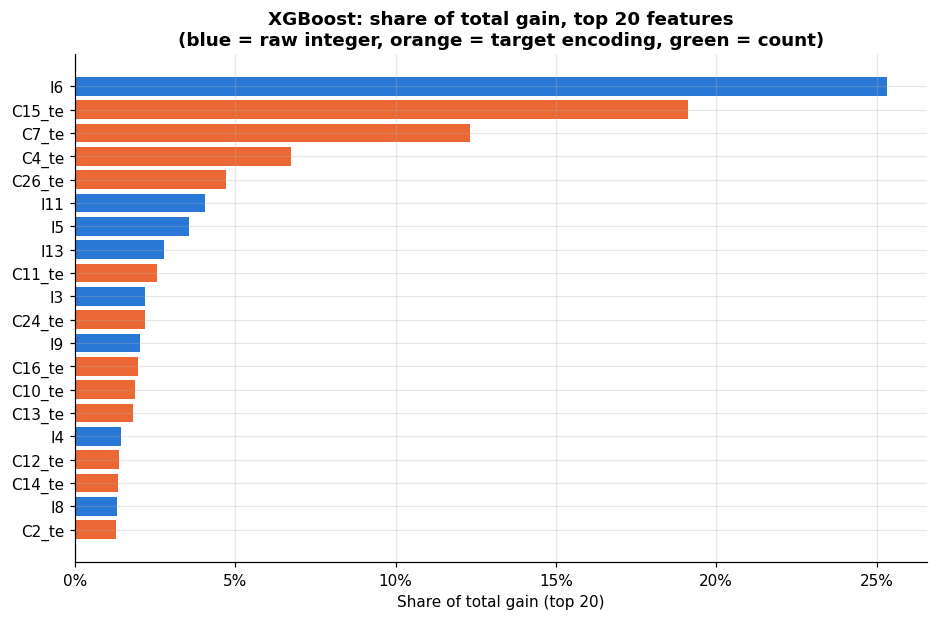

In [12]:
# ==============================
# 6.2 M2 XGBoost: feature matrix (raw integers + count + out-of-fold target encodings)
# ==============================
import xgboost as xgb

def train_count(c):
    s = df[c].to_numpy(np.int64)
    vals, cnt = np.unique(s[tr_m], return_counts=True)
    pos = np.clip(np.searchsorted(vals, s), 0, len(vals) - 1)
    return np.where(vals[pos] == s, cnt[pos], 0).astype(np.float32)

def oof_target_encoding(codes, n_folds=5, m=M_PRIOR):
    K = int(codes.max()) + 1
    out = np.empty(len(codes), dtype=np.float32)
    tr_idx = np.where(tr_m)[0]
    fold = np.random.default_rng(SEED).integers(0, n_folds, len(tr_idx))
    s_all = np.bincount(codes[tr_idx], weights=y[tr_idx], minlength=K)
    n_all = np.bincount(codes[tr_idx], minlength=K)
    for f in range(n_folds):
        idx = tr_idx[fold == f]
        s_f = np.bincount(codes[idx], weights=y[idx], minlength=K)
        n_f = np.bincount(codes[idx], minlength=K)
        out[idx] = ((s_all - s_f + m * P0) / (n_all - n_f + m))[codes[idx]]
    rest = ~tr_m
    out[rest] = ((s_all + m * P0) / (n_all + m))[codes[rest]]
    return out

t0 = time.time()
GB_NAMES = INT_COLS + [f"{c}_count" for c in CAT_COLS] + [f"{c}_te" for c in CAT_COLS] + ["n_missing"]
X_GB = np.empty((len(df), len(GB_NAMES)), dtype=np.float32)
X_GB[:, :13] = df[INT_COLS].to_numpy(np.float32)
for k, c in enumerate(CAT_COLS):
    X_GB[:, 13 + k] = train_count(c)
    X_GB[:, 39 + k] = oof_target_encoding(X_ENC[:, FEATS.index(c)])
X_GB[:, 65] = df[INT_COLS].isna().sum(axis=1).values + (df[CAT_COLS] == 0).sum(axis=1).values
print(f"Feature matrix: {X_GB.shape} built in {(time.time() - t0) / 60:.1f} min")

# ==============================
# 6.2.1 Training on GPU with early stopping
# ==============================
dtrain = xgb.QuantileDMatrix(X_GB[tr_m], y_tr, feature_names=GB_NAMES, max_bin=256)
dvalid = xgb.QuantileDMatrix(X_GB[va_m], y_va, feature_names=GB_NAMES, ref=dtrain)
params = dict(objective="binary:logistic", eval_metric="logloss", device="cuda", tree_method="hist",
              max_depth=8, eta=0.08, subsample=0.8, colsample_bytree=0.8, min_child_weight=100,
              reg_lambda=1.0, seed=SEED)
t0 = time.time()
bst = xgb.train(params, dtrain, num_boost_round=3000, evals=[(dvalid, "valid")],
                early_stopping_rounds=50, verbose_eval=100)
print(f"Best iteration: {bst.best_iteration} | training time: {(time.time() - t0) / 60:.1f} min")

for s in ["valid", "test"]:
    p = bst.inplace_predict(X_GB[MASKS[s]], iteration_range=(0, bst.best_iteration + 1))
    evaluate("M2 XGBoost (GPU)", s, p)
show_results()

imp = pd.Series(bst.get_score(importance_type="total_gain")).sort_values(ascending=False).head(20)
fig, ax = plt.subplots(figsize=(10, 6))
cmap = {"_te": ORANGE, "_count": GREEN}
ax.barh(imp.index[::-1], imp.values[::-1] / imp.sum(),
        color=[next((v for k, v in cmap.items() if n.endswith(k)), BLUE) for n in imp.index[::-1]])
ax.set(title="XGBoost: share of total gain, top 20 features\n(blue = raw integer, orange = target encoding, green = count)",
       xlabel="Share of total gain (top 20)")
pct_axis(ax, "x")
plt.show()

### 6.3 Factorization Machine (M3)

The FM extends logistic regression with an embedding **v** of size *k* for every feature value. The score of an impression is:

score = bias + Σ w_i + Σ_{i<j} ⟨v_i, v_j⟩

- The second term models **all 741 pairwise interactions** among the 39 features, each through a dot product of embeddings.
- **Why it generalizes:** the embedding of a value is learned from *all* the impressions where it appears, paired with any other feature. Two values never seen together can still get a sensible interaction score, which matters given the sparsity found in the EDA.
- It is computed in O(39·k) per impression with the identity Σ_{i<j}⟨v_i, v_j⟩ = ½ (‖Σ v_i‖² − Σ ‖v_i‖²).
- The embedding size *k* is tuned on validation (8, 16, 32).

In [13]:
# ==============================
# 6.3 M3 Factorization Machine
# ==============================
class FM(CTRModel):
    def __init__(self, k=16):
        super().__init__()
        self.w = nn.Embedding(N_EMB, 1)
        self.v = nn.Embedding(N_EMB, k)
        nn.init.zeros_(self.w.weight)
        nn.init.normal_(self.v.weight, std=0.01)
        self.bias = nn.Parameter(torch.tensor([np.log(P0 / (1 - P0))], dtype=torch.float32))

    def fm_terms(self, x):
        i = self.idx(x)
        e = self.v(i)                                                        # (B, 39, k)
        linear = self.w(i).sum(dim=(1, 2))
        pairwise = 0.5 * (e.sum(1).pow(2) - e.pow(2).sum(1)).sum(1)
        return linear, pairwise, e

    def forward(self, x):
        linear, pairwise, _ = self.fm_terms(x)
        return linear + pairwise + self.bias

fm_runs = {}
for k in [8, 16, 32]:
    print(f"FM with k = {k}")
    torch.manual_seed(SEED)
    m = FM(k)
    log = train_ctr(m, f"FM k={k}", lr=1e-3, weight_decay=1e-7)
    fm_runs[k] = (m, log["valid_logloss"].min())

best_k = min(fm_runs, key=lambda k: fm_runs[k][1])
fm_model = fm_runs[best_k][0]
print(f"\nBest embedding size: k = {best_k} (valid logloss {fm_runs[best_k][1]:.5f})")
for s in ["valid", "test"]:
    evaluate(f"M3 Factorization Machine (k={best_k})", s, predict(fm_model, s))
show_results()

FM with k = 8
  epoch 1 | train 0.46466 | valid logloss 0.45951 | AUC 0.7920 | 4s
  epoch 2 | train 0.44830 | valid logloss 0.45723 | AUC 0.7946 | 4s
  epoch 3 | train 0.43957 | valid logloss 0.45834 | AUC 0.7937 | 4s
  Early stopping (validation log loss went up).
FM with k = 16
  epoch 1 | train 0.46312 | valid logloss 0.45782 | AUC 0.7939 | 4s
  epoch 2 | train 0.44324 | valid logloss 0.45739 | AUC 0.7949 | 4s
  epoch 3 | train 0.43044 | valid logloss 0.46116 | AUC 0.7921 | 4s
  Early stopping (validation log loss went up).
FM with k = 32
  epoch 1 | train 0.46251 | valid logloss 0.45783 | AUC 0.7939 | 5s
  epoch 2 | train 0.43839 | valid logloss 0.46027 | AUC 0.7925 | 5s
  Early stopping (validation log loss went up).

Best embedding size: k = 8 (valid logloss 0.45723)


### 6.2–6.3 XGBoost and FM — Key Findings

| Model | Split | Log loss | AUC | Log-loss reduction | Calibration |
|---|---|---|---|---|---|
| M1 Logistic regression | test | 0.46721 | 0.7844 | 18.40% | 1.017 |
| M3 Factorization Machine (k = 8) | valid | 0.45723 | 0.7946 | 19.81% | 1.016 |
| M3 Factorization Machine (k = 8) | test | 0.46063 | 0.7923 | 19.54% | 1.012 |
| M2 XGBoost (GPU) | valid | 0.45049 | 0.8014 | 21.00% | 1.012 |
| M2 XGBoost (GPU) | test | **0.45389** | **0.7991** | **20.72%** | **1.006** |

**1. Learning interactions pays off.** On test, both models with interactions clearly beat the additive logistic regression:
- **FM:** −0.0066 in log loss (AUC +0.008);
- **XGBoost:** **−0.0133** in log loss (AUC +0.015).

At this scale, gains of 0.001 are considered significant, so these are large improvements. They confirm the pairwise-interaction findings of Section 4.5.

**2. XGBoost is the best model so far, and it trains fast.**
- Test log loss **0.4539**, AUC **0.799**, and the best calibration so far (only +0.6% over-prediction).
- It used **2,592 trees** before early stopping, but the last \~1,000 improved validation log loss by less than 0.0001: the model is saturated with these features.
- Training took **1.1 minutes** on the GPU for 6.5M impressions × 66 features.
- For reference, published deep CTR models trained on the *full* dataset with a random split report AUC around 0.80. We get close with **one fifth of the data** and a stricter **temporal** split.

**3. What XGBoost relies on.**
- **I6** alone accounts for **25%** of the total gain, which matches its rank as the best single feature (4.1) and its many interactions (4.5).
- It is followed by the **target encodings** of **C15 (19%)**, **C7 (12%)**, **C4 (7%)** and **C26 (5%)**, and the integers I11, I5 and I13.
- **No count encoding appears in the top 20**: once the target encoding is available, how frequent a value is adds little. The frequency effect seen in 4.3 is already absorbed by the smoothed CTR, which shrinks rare values toward the global mean.

**4. The FM overfits quickly, and smaller embeddings work best.**
- The best embedding size is the smallest one tested, **k = 8** (validation 0.4572). In every run, validation log loss is best after **epoch 1** and worsens after (e.g., 0.4578 → 0.4603), while training loss drops sharply (0.463 → 0.438).
- With 254k values × 8 dimensions, the FM has \~2M parameters. Many values appear only a few dozen times, so their embeddings memorize noise.
- The FM still captures part of the interactions, but **less efficiently than the trees**, which also benefit from out-of-fold target encodings that pool information smoothly.

**Implication:** the neural model (DeepFM) needs **stronger regularization** (dropout, a small embedding size) to compete. Since trees and factorization models learn interactions in very different ways, an **ensemble** of the two is promising.

### 6.4 DeepFM (M4)

DeepFM adds a neural network on top of the FM, **sharing the same embeddings**:

score = bias + Σ w_i + Σ_{i<j} ⟨v_i, v_j⟩ + MLP([v_1, …, v_39])

- **FM component:** first-order weights and all pairwise interactions (as in M3).
- **Deep component:** the 39 embeddings are concatenated (39·k inputs) and passed through 3 hidden layers of 400 units (ReLU, BatchNorm, dropout). It can learn **higher-order interactions** (three or more features at once) and non-linear patterns.
- Both components are trained jointly end to end. Since the embeddings receive gradients from both, the deep part also acts as an extra signal for learning them.
- **Regularization**, motivated by the FM's fast overfitting: dropout 0.3 in the network, and small embeddings (k = 8 and 16 are compared on validation).

In [14]:
# ==============================
# 6.4 M4 DeepFM
# ==============================
class DeepFM(FM):
    def __init__(self, k=16, hidden=(400, 400, 400), dropout=0.3):
        super().__init__(k)
        layers, d_in = [], len(FEATS) * k
        for h in hidden:
            layers += [nn.Linear(d_in, h), nn.BatchNorm1d(h), nn.ReLU(), nn.Dropout(dropout)]
            d_in = h
        layers.append(nn.Linear(d_in, 1))
        self.mlp = nn.Sequential(*layers)

    def forward(self, x):
        linear, pairwise, e = self.fm_terms(x)
        deep = self.mlp(e.flatten(1)).squeeze(1)
        return linear + pairwise + deep + self.bias

deep_runs = {}
for k in [8, 16]:
    print(f"DeepFM with k = {k}")
    torch.manual_seed(SEED)
    m = DeepFM(k=k)
    log = train_ctr(m, f"DeepFM k={k}", lr=1e-3, weight_decay=1e-7)
    deep_runs[k] = (m, log["valid_logloss"].min())

best_k_deep = min(deep_runs, key=lambda k: deep_runs[k][1])
deepfm_model = deep_runs[best_k_deep][0]
DEEP_NAME = f"M4 DeepFM (k={best_k_deep})"
print(f"\nBest embedding size: k = {best_k_deep} (valid logloss {deep_runs[best_k_deep][1]:.5f})")
for s in ["valid", "test"]:
    evaluate(DEEP_NAME, s, predict(deepfm_model, s))
show_results()

DeepFM with k = 8
  epoch 1 | train 0.46056 | valid logloss 0.45443 | AUC 0.7972 | 8s
  epoch 2 | train 0.44430 | valid logloss 0.45257 | AUC 0.7994 | 7s
  epoch 3 | train 0.43405 | valid logloss 0.45446 | AUC 0.7978 | 7s
  Early stopping (validation log loss went up).
DeepFM with k = 16
  epoch 1 | train 0.46012 | valid logloss 0.45427 | AUC 0.7973 | 8s
  epoch 2 | train 0.44291 | valid logloss 0.45272 | AUC 0.7992 | 8s
  epoch 3 | train 0.43002 | valid logloss 0.45642 | AUC 0.7963 | 7s
  Early stopping (validation log loss went up).

Best embedding size: k = 8 (valid logloss 0.45257)


### 6.5 Ensemble: XGBoost + DeepFM (M5)

Trees and factorization models learn interactions in different ways: axis-aligned splits on encoded statistics vs. dot products of learned embeddings. Their errors should be only partly correlated.

The ensemble averages the two models in **logit space** (weighted average of log-odds, then sigmoid), which keeps probabilities well calibrated. The weight is chosen on **validation**, and the test set is used once.

Correlation of the two models' logits on validation: 0.951


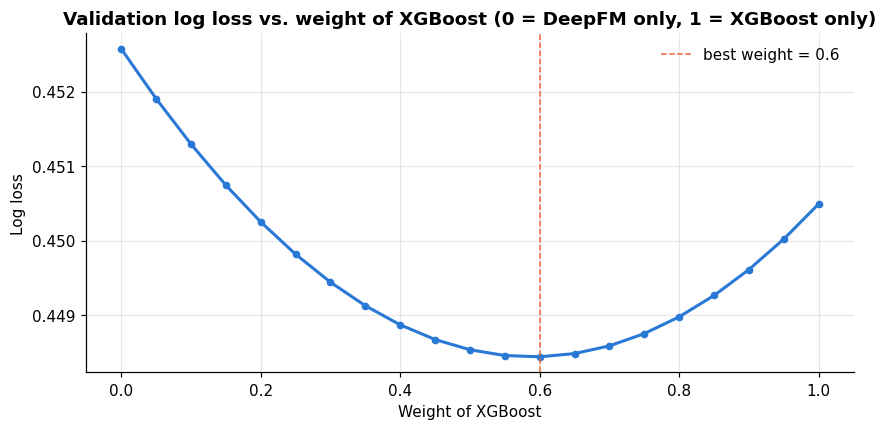

,,logloss,AUC,LL_gain,calib_ratio
model,split,,,,
M0 Global CTR,test,0.57253,0.5000,0.00%,0.984
M1 Logistic regression,test,0.46721,0.7844,18.40%,1.017
M2 XGBoost (GPU),test,0.45389,0.7991,20.72%,1.006
M3 Factorization Machine (k=8),test,0.46063,0.7923,19.54%,1.012
M4 DeepFM (k=8),test,0.45605,0.7972,20.35%,0.972
M5 Ensemble XGBoost + DeepFM (w=0.6),test,0.45182,0.8016,21.08%,0.988


In [15]:
# ==============================
# 6.5 M5 Ensemble in logit space
# ==============================
def logit(p):
    p = np.clip(p, 1e-7, 1 - 1e-7)
    return np.log(p / (1 - p))

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

A, B = "M2 XGBoost (GPU)", DEEP_NAME
la_va, lb_va = logit(PREDS[(A, "valid")]), logit(PREDS[(B, "valid")])
print(f"Correlation of the two models' logits on validation: {np.corrcoef(la_va, lb_va)[0, 1]:.3f}")

weights = np.round(np.linspace(0, 1, 21), 2)
ens = pd.DataFrame([{"w_xgb": w, **evaluate("tmp", "valid", sigmoid(w * la_va + (1 - w) * lb_va), store=False)}
                    for w in weights])
best_w = float(ens.loc[ens["logloss"].idxmin(), "w_xgb"])

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(ens["w_xgb"], ens["logloss"], color=BLUE, lw=2, marker="o", ms=4)
ax.axvline(best_w, color=ORANGE, ls="--", lw=1, label=f"best weight = {best_w}")
ax.set(title="Validation log loss vs. weight of XGBoost (0 = DeepFM only, 1 = XGBoost only)",
       xlabel="Weight of XGBoost", ylabel="Log loss")
ax.legend(frameon=False)
plt.show()

ENS_NAME = f"M5 Ensemble XGBoost + DeepFM (w={best_w})"
for s in ["valid", "test"]:
    z = best_w * logit(PREDS[(A, s)]) + (1 - best_w) * logit(PREDS[(B, s)])
    evaluate(ENS_NAME, s, sigmoid(z))
show_results("test")

### 6.4–6.5 DeepFM and Ensemble — Key Findings

| Model (test) | Log loss | AUC | Log-loss reduction | Calibration |
|---|---|---|---|---|
| M1 Logistic regression | 0.46721 | 0.7844 | 18.40% | 1.017 |
| M3 Factorization Machine (k = 8) | 0.46063 | 0.7923 | 19.54% | 1.012 |
| M4 DeepFM (k = 8) | 0.45605 | 0.7972 | 20.35% | 0.972 |
| M2 XGBoost (GPU) | 0.45389 | 0.7991 | 20.72% | 1.006 |
| **M5 Ensemble XGBoost + DeepFM (w = 0.6)** | **0.45182** | **0.8016** | **21.08%** | 0.988 |

**1. The deep component improves the FM substantially.**
- On test, DeepFM lowers log loss by **0.0046** vs. the FM (0.4560 vs. 0.4606) and raises AUC by 0.005, with the same embedding size (k = 8, again the best).
- The network on top of the shared embeddings captures **higher-order and non-linear interactions** that dot products alone miss. Dropout and BatchNorm keep it from overfitting as fast as the plain FM.

**2. XGBoost still wins as a single model, but by little.**
- XGBoost beats DeepFM by **0.0022** in log loss. Trees with out-of-fold target encodings remain very strong on tabular data with high-cardinality features.
- DeepFM learns everything (embeddings and interactions) from raw codes, end to end, without any manual feature engineering.

**3. The ensemble is the best model: AUC above 0.80 on a held-out future day.**
- Test log loss **0.4518** (−0.0021 vs. XGBoost) and **AUC 0.8016** (+0.0025).
- The logits of the two models are correlated at **0.951**: similar, but different enough to correct each other's errors.
- The validation curve is smooth and U-shaped, with its minimum at **60% XGBoost / 40% DeepFM**. Both models contribute.

**4. Calibration varies across models.**
- XGBoost over-predicts by +0.6% on test, while DeepFM **under-predicts by 2.8%** (its BatchNorm and dropout shift the average output).
- The ensemble falls in between (−1.2%). Section 7 measures calibration in detail and tests a simple recalibration step.

**Progress over the global CTR baseline (test):** logistic regression 18.4% → FM 19.5% → DeepFM 20.4% → XGBoost 20.7% → **ensemble 21.1%**.

## 7. Model Analysis

### 7.1 Calibration
Bids are computed as pCTR × value per click, so a predicted 30% must mean 30%.
- **Reliability curve:** test impressions are grouped into 20 equal-size bins by predicted CTR, and the mean prediction is compared with the observed click rate in each bin (perfect = diagonal).
- **Expected Calibration Error (ECE):** the impression-weighted average gap |predicted − observed| across bins.
- **Platt recalibration:** a one-feature logistic regression on the ensemble's logit, fitted on **validation** and applied to **test**. It corrects systematic bias without changing the ranking (AUC stays the same).

Platt mapping: logit' = 1.023 · logit + +0.029


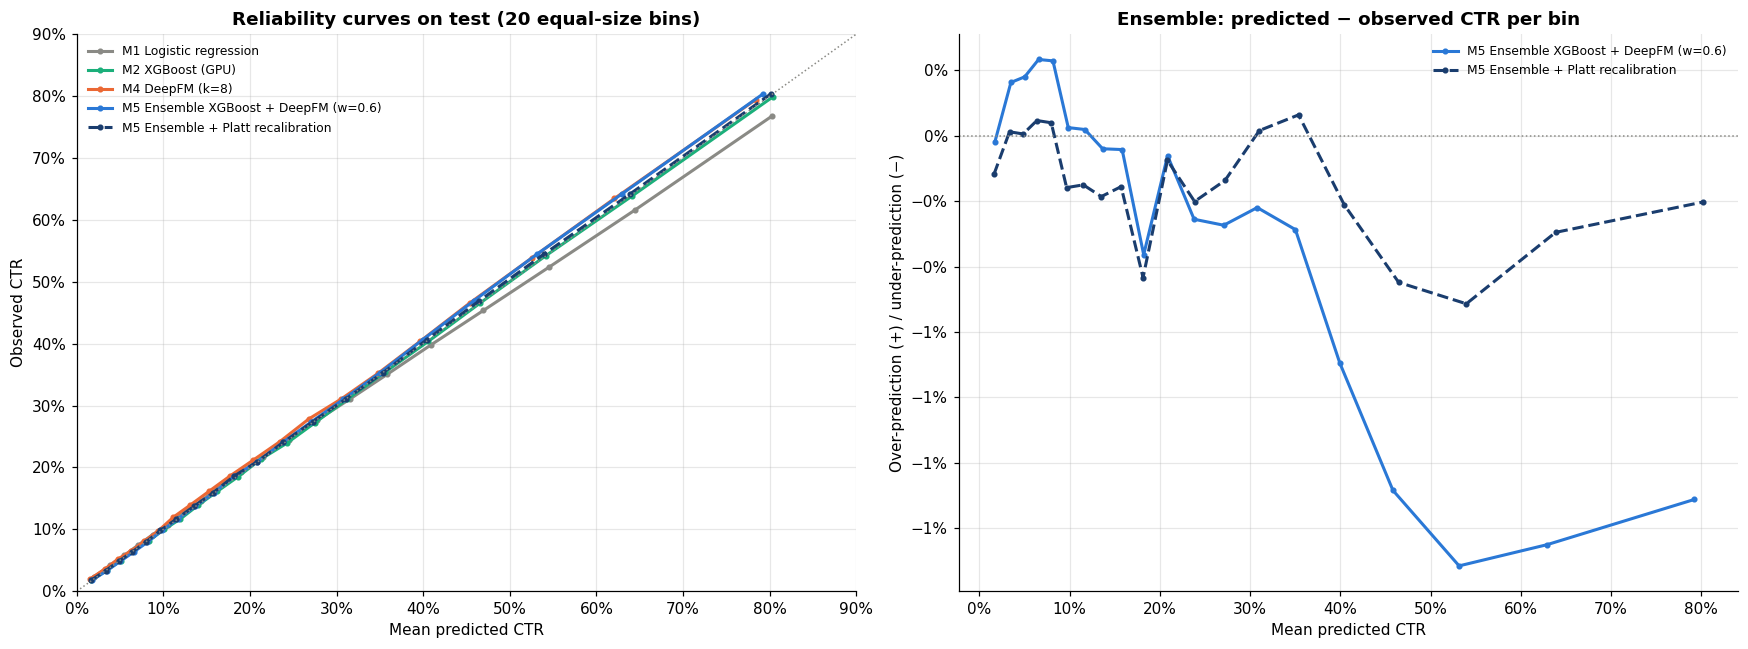

,ECE,mean_pred,actual_CTR
model,,,
M1 Logistic regression,0.813%,26.40%,25.95%
M2 XGBoost (GPU),0.168%,26.09%,25.95%
M4 DeepFM (k=8),0.732%,25.21%,25.95%
M5 Ensemble XGBoost + DeepFM (w=0.6),0.393%,25.64%,25.95%
M5 Ensemble + Platt recalibration,0.173%,25.79%,25.95%


,,logloss,AUC,LL_gain,calib_ratio
model,split,,,,
M0 Global CTR,test,0.57253,0.5000,0.00%,0.984
M1 Logistic regression,test,0.46721,0.7844,18.40%,1.017
M2 XGBoost (GPU),test,0.45389,0.7991,20.72%,1.006
M3 Factorization Machine (k=8),test,0.46063,0.7923,19.54%,1.012
M4 DeepFM (k=8),test,0.45605,0.7972,20.35%,0.972
M5 Ensemble XGBoost + DeepFM (w=0.6),test,0.45182,0.8016,21.08%,0.988
M5 Ensemble + Platt recalibration,test,0.45175,0.8016,21.10%,0.994


In [16]:
# ==============================
# 7.1 Calibration: reliability curves, ECE and Platt recalibration
# ==============================
from sklearn.linear_model import LogisticRegression

y_te = y[te_m]
CAL_MODELS = {"M1 Logistic regression": GREY, "M2 XGBoost (GPU)": GREEN, DEEP_NAME: ORANGE, ENS_NAME: BLUE}

def reliability(p, yt, bins=20):
    q = pd.qcut(p, bins, labels=False, duplicates="drop")
    d = pd.DataFrame({"p": p, "y": yt, "q": q}).groupby("q").agg(pred=("p", "mean"), obs=("y", "mean"), n=("y", "size"))
    ece = (d["n"] * (d["pred"] - d["obs"]).abs()).sum() / d["n"].sum()
    return d, ece

# Platt recalibration of the ensemble (fitted on validation, applied to test)
platt = LogisticRegression(C=1e6).fit(logit(PREDS[(ENS_NAME, "valid")]).reshape(-1, 1), y_va)
p_cal = platt.predict_proba(logit(PREDS[(ENS_NAME, "test")]).reshape(-1, 1))[:, 1]
CAL_NAME = "M5 Ensemble + Platt recalibration"
evaluate(CAL_NAME, "test", p_cal)
print(f"Platt mapping: logit' = {platt.coef_[0, 0]:.3f} · logit + {platt.intercept_[0]:+.3f}")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
ece_rows = []
for name, c in {**CAL_MODELS, CAL_NAME: "#1a3d6e"}.items():
    d, ece = reliability(PREDS[(name, "test")], y_te)
    ece_rows.append({"model": name, "ECE": ece, "mean_pred": PREDS[(name, "test")].mean(), "actual_CTR": y_te.mean()})
    ls = "--" if name == CAL_NAME else "-"
    axes[0].plot(d["pred"], d["obs"], color=c, lw=2, ls=ls, marker="o", ms=3, label=name)
axes[0].plot([0, 1], [0, 1], color=GREY, ls=":", lw=1)
axes[0].set(title="Reliability curves on test (20 equal-size bins)", xlabel="Mean predicted CTR", ylabel="Observed CTR",
            xlim=(0, 0.9), ylim=(0, 0.9))
pct_axis(axes[0]); pct_axis(axes[0], "x")
axes[0].legend(frameon=False, fontsize=8)

# Gap per bin for the ensemble, before and after recalibration
for name, c, ls in [(ENS_NAME, BLUE, "-"), (CAL_NAME, "#1a3d6e", "--")]:
    d, _ = reliability(PREDS[(name, "test")], y_te)
    axes[1].plot(d["pred"], d["pred"] - d["obs"], color=c, lw=2, ls=ls, marker="o", ms=3, label=name)
axes[1].axhline(0, color=GREY, ls=":", lw=1)
axes[1].set(title="Ensemble: predicted − observed CTR per bin", xlabel="Mean predicted CTR",
            ylabel="Over-prediction (+) / under-prediction (−)")
pct_axis(axes[1]); pct_axis(axes[1], "x")
axes[1].legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

display(pd.DataFrame(ece_rows).set_index("model").style.format({"ECE": "{:.3%}", "mean_pred": "{:.2%}", "actual_CTR": "{:.2%}"}))
show_results("test")

### 7.2 Segments and Business Value

**Segments (test):**
- **Unseen IDs:** impressions whose finest ID-like feature (C3) never appeared in training (31% of test), vs. known IDs.
- **Missing data:** impressions grouped by how many of their 39 features are missing.

**Business value: gain curve.** Suppose the advertiser's budget only covers a fraction of the available impressions. Ranking impressions by predicted CTR and buying the top ones, what share of all clicks do we capture, compared with buying at random?

By C3:


,share,CTR,M1 logloss,M1 AUC,M2 logloss,M2 AUC,M4 logloss,M4 AUC,M5 logloss,M5 AUC
segment,,,,,,,,,,
known ID,69.7%,25.21%,0.4581,0.7883,0.4440,0.8037,0.4464,0.8014,0.4420,0.8060
unseen ID,30.3%,27.63%,0.4881,0.7746,0.4765,0.7878,0.4781,0.7866,0.4743,0.7907


By n_missing:


,share,CTR,M1 logloss,M1 AUC,M2 logloss,M2 AUC,M4 logloss,M4 AUC,M5 logloss,M5 AUC
segment,,,,,,,,,,
0–3,31.6%,28.39%,0.4957,0.7723,0.4805,0.7887,0.4833,0.7861,0.4782,0.7914
4–5,22.5%,25.40%,0.4521,0.7969,0.4398,0.8099,0.4417,0.8084,0.4378,0.8123
6–8,27.3%,26.43%,0.4735,0.7815,0.4609,0.7957,0.4629,0.7938,0.4591,0.7980
9+,18.6%,21.74%,0.4279,0.7874,0.4155,0.8027,0.4171,0.8013,0.4135,0.8054


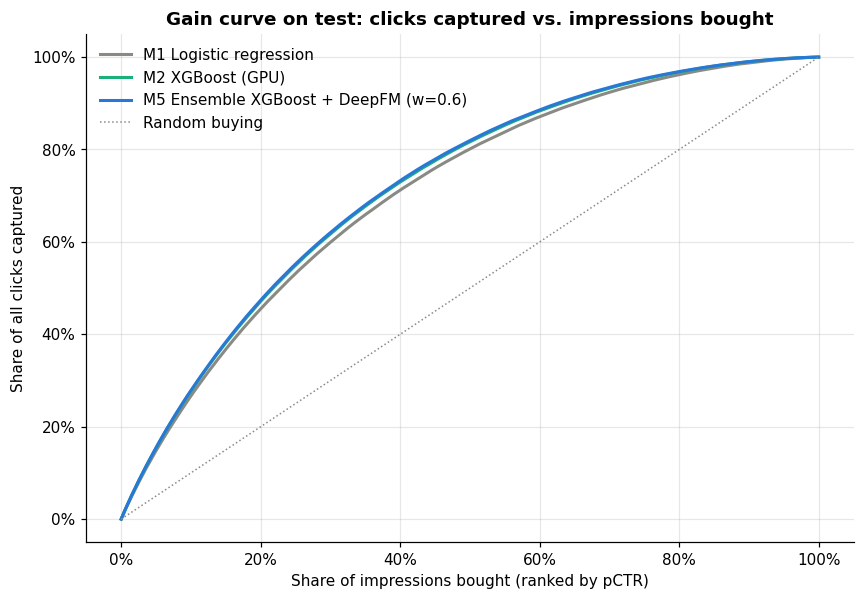

In [17]:
# ==============================
# 7.2.1 Performance by segment (test)
# ==============================
te_idx = np.where(te_m)[0]
SEG_MODELS = ["M1 Logistic regression", "M2 XGBoost (GPU)", DEEP_NAME, ENS_NAME]
segments = {
    "C3": np.where(np.isin(df["C3"].values[te_idx], np.unique(df["C3"].values[tr_m])), "known ID", "unseen ID"),
    "n_missing": pd.cut(X_GB[te_m, 65], [-1, 3, 5, 8, 39], labels=["0–3", "4–5", "6–8", "9+"]).astype(str),
}
for seg_name, seg in segments.items():
    rows = []
    for g in sorted(pd.unique(seg)):
        m = seg == g
        row = {"segment": g, "share": m.mean(), "CTR": y_te[m].mean()}
        for name in SEG_MODELS:
            p = PREDS[(name, "test")][m]
            row[f"{name.split(' ')[0]} logloss"] = log_loss(y_te[m], p)
            row[f"{name.split(' ')[0]} AUC"] = roc_auc_score(y_te[m], p)
        rows.append(row)
    t = pd.DataFrame(rows).set_index("segment")
    print(f"By {seg_name}:")
    display(t.style.format({**{c: "{:.4f}" for c in t.columns if "logloss" in c or "AUC" in c},
                            "share": "{:.1%}", "CTR": "{:.2%}"}))

# ==============================
# 7.2.2 Gain curve: share of clicks captured when buying the top-ranked impressions
# ==============================
fig, ax = plt.subplots(figsize=(9, 6))
fracs = np.linspace(0, 1, 201)
gain_rows = []
for name, c in [("M1 Logistic regression", GREY), ("M2 XGBoost (GPU)", GREEN), (ENS_NAME, BLUE)]:
    order = np.argsort(-PREDS[(name, "test")])
    cum = np.concatenate([[0], np.cumsum(y_te[order])]) / y_te.sum()
    curve = cum[(fracs * len(order)).astype(int)]
    ax.plot(fracs, curve, color=c, lw=2, label=name)
    for f in (0.05, 0.10, 0.20, 0.50):
        k = int(f * len(order))
        gain_rows.append({"model": name, "top_impressions": f, "clicks_captured": cum[k],
                          "CTR_of_bought": y_te[order[:k]].mean(), "lift": y_te[order[:k]].mean() / y_te.mean()})
ax.plot([0, 1], [0, 1], color=GREY, ls=":", lw=1, label="Random buying")
ax.set(title="Gain curve on test: clicks captured vs. impressions bought", xlabel="Share of impressions bought (ranked by pCTR)",
       ylabel="Share of all clicks captured")
pct_axis(ax); pct_axis(ax, "x")
ax.legend(frameon=False)
plt.show()

g = pd.DataFrame(gain_rows).pivot(index="top_impressions", columns="model", values=["clicks_captured", "lift"])
display(g.style.format("{:.2f}").format("{:.1%}", subset="clicks_captured"))

### 7. Model Analysis — Key Findings

**1. All models are well calibrated, and XGBoost and the recalibrated ensemble are almost perfect.**

| Model (test) | ECE | Mean prediction | Actual CTR |
|---|---|---|---|
| M1 Logistic regression | 0.81% | 26.40% | 25.95% |
| M4 DeepFM | 0.73% | 25.21% | 25.95% |
| M5 Ensemble | 0.39% | 25.64% | 25.95% |
| M2 XGBoost | **0.17%** | 26.09% | 25.95% |
| **M5 Ensemble + Platt** | **0.17%** | 25.79% | 25.95% |

- Every reliability curve lies close to the diagonal, from 2% to 80% predicted CTR. Log loss trains models to output honest probabilities.
- **Logistic regression over-predicts the most promising impressions**: when it predicts \~80%, the observed CTR is \~77%. An additive model cannot capture that strong signals overlap, so it double-counts them. For bidding, this means **overpaying exactly on the most expensive impressions**.
- The ensemble slightly **under-predicts high-CTR impressions** (by about 1–1.5 pp above 40% predicted), inherited from DeepFM.
- **Platt recalibration** (fitted on validation: logit' = 1.023 · logit + 0.029) halves the remaining gap at the top, cuts ECE from 0.39% to **0.17%** and brings the mean prediction to 25.79% vs. 25.95% actual. Log loss improves only slightly (0.45182 → 0.45175) and AUC is unchanged, as expected from a monotonic transformation.

**2. New IDs are harder, but the models generalize.**
- **30.3%** of test impressions carry a C3 value never seen in training. Their CTR is higher (27.6% vs. 25.2%).
- The ensemble's AUC drops from **0.806** (known IDs) to **0.791** (unseen IDs), and log loss rises from 0.442 to 0.474.
- The drop is moderate. Even for a completely new fine-grained ID, the coarser levels of the hierarchy (C24, C4) and the other 37 features still carry most of the signal.
- The ensemble is the best model in **both** segments, and its margin over logistic regression is the same (+0.016 AUC), so its advantage does not depend on memorizing known IDs.

**3. More complete impressions are *not* easier to predict.**
- The impressions with the fewest missing values (0–3, 31.6% of test) have the **highest CTR (28.4%)** but the **lowest AUC (0.791)**.
- Impressions with 4–5 missing values are the easiest to rank (AUC **0.812**). Those with 9 or more have the lowest CTR (21.7%) and an AUC of 0.805.
- The missing-value pattern seems to identify **different types of traffic** (e.g., placements or devices that log different signals) rather than data quality. This supports encoding missingness explicitly.
- Log loss is not comparable across these segments, since it depends on each segment's base CTR. AUC is the fair comparison.

**4. Business value: buying the top 20% of impressions captures almost half of the clicks.**

| Impressions bought (ranked by pCTR) | Clicks captured (ensemble) | Lift | Clicks captured (logistic regression) |
|---|---|---|---|
| Top 5% | 15.5% | **3.10×** | 14.8% |
| Top 10% | 27.8% | 2.78× | 26.7% |
| Top 20% | **47.4%** | 2.37× | 45.5% |
| Top 50% | 81.9% | 1.64× | 80.1% |

- With a budget for **20% of the impressions**, ranking by the ensemble's pCTR captures **47.4% of all clicks**: an impression bought this way is **2.37× more likely to be clicked** than one bought at random.
- Compared with logistic regression, the ensemble captures **+1.9 pp more clicks for the same budget** (+4.2% relative). At ad-tech scale (billions of impressions per day), that difference is large in absolute terms.

## 8. Conclusions

### 8.1 Final Results (Test = Day 7, 1.31M Impressions Never Used for Training or Tuning)

| Model | Approach | Log loss | AUC | Log-loss reduction | ECE |
|---|---|---|---|---|---|
| M0 Global CTR | Baseline | 0.57253 | 0.5000 | 0.00% | — |
| M1 Logistic regression | Linear, one-hot | 0.46721 | 0.7844 | 18.40% | 0.81% |
| M3 Factorization Machine (k = 8) | Pairwise interactions via embeddings | 0.46063 | 0.7923 | 19.54% | — |
| M4 DeepFM (k = 8) | FM + neural network | 0.45605 | 0.7972 | 20.35% | 0.73% |
| M2 XGBoost (GPU) | Trees on target / count encodings | 0.45389 | 0.7991 | 20.72% | 0.17% |
| M5 Ensemble XGBoost + DeepFM | Logit average (60 / 40) | 0.45182 | 0.8016 | 21.08% | 0.39% |
| **M5 + Platt recalibration** | **Final model** | **0.45175** | **0.8016** | **21.10%** | **0.17%** |

The final model reduces log loss by **21.1%** vs. the global CTR, beats logistic regression (the classic industry baseline) by **0.0155** in log loss and **+0.017** in AUC, and is calibrated to within **0.2 pp** on a future day. All of this uses one fifth of the dataset and a strict temporal split.

### 8.2 Answers to the Business Questions

- **Can we predict whether an impression will be clicked?** Yes. The model separates clicks from non-clicks with **AUC 0.80**: buying the top 5% of impressions yields a click rate **3.1× the average**, and the top 20% captures **47%** of all clicks.
- **Are the probabilities reliable enough for bidding?** Yes. After recalibration, the average gap between predicted and observed CTR is **0.17 pp**. Logistic regression systematically overpays for the most promising impressions; the final model does not.
- **Do feature interactions matter?** Yes. Every model that learns interactions beats the additive one, with improvements of 0.007–0.016 in log loss, far above the 0.001 usually considered significant.
- **Deep learning or gradient boosting?** Both. XGBoost is the best single model, DeepFM is close, and **their ensemble beats both**: they learn interactions in different ways.

### 8.3 Key Learnings

1. **No feature is strong on its own; everything comes from combining many weak signals.** The best single feature reduces log loss by 6.9%. All 39 features together, additively, reach 18.4%, and with interactions 21.1%.
2. **Handling high cardinality is the core engineering problem.** 9.2M distinct categorical values, 31.7% of test impressions with unseen values, and six ID-like features forming one hierarchy. Grouping rare values into `<OOV>` (36× compression), keeping missingness as a category, and using smoothed out-of-fold target encodings made the problem tractable.
3. **Missingness is information.** Missing values change CTR by factors of 0.37–1.27, and the missing-value pattern defines traffic segments with different behavior.
4. **CTR models overfit after one epoch.** LR, FM and DeepFM all peaked after a single pass over the data, and smaller embeddings (k = 8) won. Early stopping on a later day is essential.
5. **Trees remain very strong on tabular data.** With good encodings, XGBoost beat the deep model and trained in about one minute on a GPU. The deep model's value appeared in the **ensemble**.
6. **Calibration must be measured, not assumed.** Models with similar AUC differed by 4× in calibration error, and a two-parameter recalibration fixed most of it.

### 8.4 Business Recommendations

| Decision | Recommendation | Why |
|---|---|---|
| Production model | **XGBoost + DeepFM ensemble with Platt recalibration** | Best log loss, AUC and calibration |
| Low-latency alternative | **XGBoost alone** | 99.5% of the ensemble's log-loss reduction, best raw calibration, simplest to serve |
| Bidding | Bid = calibrated pCTR × value per click | Calibration within 0.2 pp avoids systematic over- or under-bidding |
| Recalibration | Refit the Platt step **daily** on the latest day | CTR drifts by \~0.4 pp between days; refitting costs seconds |
| Retraining | Retrain the models frequently (e.g., daily) | 30% of impressions carry new IDs every day |
| Production CTR | **Correct for the negative subsampling** | The data's CTR (25.6%) is inflated by subsampled non-clicks; probabilities must be mapped back to the real base rate |

### 8.5 Limitations

- **One-fifth sample:** the full dataset would reduce unseen categories and allow larger embeddings. Absolute metrics would likely improve somewhat.
- **Approximate days:** the file has no timestamps, so days are approximated as equal slices of the chronologically ordered rows.
- **Anonymous features:** no domain interpretation is possible, so the explanations of feature behavior (engagement counts, ad fatigue) are hypotheses.
- **Light tuning, single seed:** hyperparameters were tuned on small grids and models were trained once. Small differences (e.g., XGBoost vs. DeepFM, 0.002) are within plausible run-to-run variation.
- **Offline evaluation only:** log loss and AUC on historical data do not measure the effect of bids on auction outcomes. Business impact requires an online A/B test.
- **Inflated base rate:** the click rate is not the real one, because Criteo subsampled non-clicks.

### 8.6 Next Steps

1. **Train on the full 45M impressions** (streaming or larger hardware), with larger embeddings and a lower `<OOV>` threshold.
2. **Stronger interaction models:** field-aware FM (the 2014 Kaggle winner), DCN-v2, or attention-based models such as AutoInt.
3. **Hierarchy-aware encodings:** use the C3 → C24 hierarchy explicitly as a backoff for unseen IDs.
4. **Robustness:** several seeds with confidence intervals, and a rolling evaluation over multiple days.
5. **Online validation:** an A/B test comparing bids from the new model with the current one, measuring cost per click and return on ad spend.

# End of execution

In [18]:
end = time.time()
delta = end - start
hours, rem = divmod(delta, 3600)
minutes, seconds = divmod(rem, 60)
print(f"Total execution time: {int(hours)}h {int(minutes)}m {seconds:.0f}s")

Total execution time: 0h 8m 37s
